In [1]:
import cobra

from cobra.io import read_sbml_model
from cobra.io import write_sbml_model
from cobra.io import from_json
from cobra import Reaction, Metabolite, Model
from cobra.util.solver import linear_reaction_coefficients
from cobra import manipulation
from cobra.flux_analysis import pfba

import escher
from escher import Builder

In [ ]:
from pybiouml import pybiouml
work = pybiouml.PyBiouml()

work.export('data/Collaborations/Bioremediation/Data/iEK643/iEK643', 
            target_file='agita_model_2710.xml',
            exporter='SBML',
            exporter_params={'saveBioUMLAnnotation': False}
           )

In [8]:
agitata = read_sbml_model('agita_model_2710.xml')

In [9]:
bigg_annotations = []
bigg_annotations = set(bigg_annotations)
for r in agitata.reactions:
    if 'bigg.reaction' in r.annotation:
        bigg_rxn_ann = r.annotation['bigg.reaction']
        bigg_rxn_ann = set(bigg_rxn_ann)
        bigg_annotations.update(bigg_rxn_ann)
# bigg_annotations

In [10]:
from collections import defaultdict

i_to_reactions = defaultdict(list)

for r in agitata.reactions:
    if 'bigg.reaction' in r.annotation:
        ann = r.annotation['bigg.reaction']
        if isinstance(ann, list):
            for i in set(ann) & bigg_annotations: 
                i_to_reactions[i].append(r.id)

for i, r_ids in i_to_reactions.items():
    if len(r_ids) >= 2:
        print(f"{i}: {r_ids}")

ACSERLm: ['rxn02571_c0', 'rxn09886_c0']
ACSERL: ['rxn02571_c0', 'rxn09886_c0']
ACSERLh: ['rxn02571_c0', 'rxn09886_c0']
HKtpp: ['rxn08762_c0', 'rxn10558_c0']
Kabc: ['rxn08762_c0', 'rxn10558_c0']
Kabcpp: ['rxn08762_c0', 'rxn10558_c0']
HKt: ['rxn08762_c0', 'rxn10558_c0']


In [55]:
agitata

Name,agita_genomic
Memory address,7f2e2d8dcb50
Number of metabolites,1827
Number of reactions,2068
Number of genes,643
Number of groups,1235
Objective expression,1.0*EX_cpd11416_c0 - 1.0*EX_cpd11416_c0_reverse_67607
Compartments,"Cytosol, Extracellular space, Periplasm"


In [11]:
agitata.remove_reactions('rxn05990_c0') #Rtotal_c cpd16496_c0
agitata.remove_reactions('rxn05824_c0') #Rtotal_c 
agitata.remove_reactions('rxn05978_c0') #D-Amino acid-c0 cpd11673_c0
agitata.remove_reactions('rxn06168_c0') #D-Amino acid-c0 
agitata.remove_reactions('rxn06281_c0') #D-Amino acid-c0 
agitata.remove_reactions('rxn06608_c0') #Amino acid-c0
agitata.remove_reactions('rxn11968_c0') #D-Amino acid-c0 
agitata.remove_reactions('rxn11997_c0') #R-S-Cysteinylglycine 
agitata.remove_reactions('rxn15536_c0') #Rtotal_c
agitata.remove_reactions('rxn05962_c0') #Rtotal_c
agitata.remove_reactions('rxn14382_c0') #L-Amino acid-c0 cpd11623_c0 rxn05824_c0
agitata.remove_reactions('rxn08762_c0') #Rtotal_c

agitata.remove_reactions('rxn10558_c0') # Duplicate_Kabc 
agitata.remove_reactions('rxn09886_c0') # Duplicate_ACSERL
# agitata.summary()

/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:777: UserWarning: need to pass in a list
  warn("need to pass in a list")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn05990_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr/local/lib/python3.9/dist-packages/cobra/core/group.py:147: UserWarning: need to pass in a list
  warn("need to pass in a list")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn05978_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn06168_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn06281_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn06608_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr

In [12]:
standard_compartments = {'c': 'cytosol', 'e': 'extracellular', 'p': 'periplasm'} #extracellular space

def fix_compartments(model, mapping):
    for m in model.metabolites:
        if m.compartment in mapping:
            m.compartment = mapping[m.compartment]
    model.compartments = standard_compartments

fix_compartments(agitata, {'c0': 'c', 'e0': 'e', 'p0': 'p'})

In [13]:
for i in range(len(agitata.reactions)):
    if 'bigg.reaction' not in (agitata.reactions[i].annotation.keys()):
        continue
    elif isinstance(agitata.reactions[i].annotation['bigg.reaction'], list):
        agitata.reactions[i].id = agitata.reactions[i].annotation['bigg.reaction'][0]
    else:
        agitata.reactions[i].id = agitata.reactions[i].annotation['bigg.reaction']

print([agitata.reactions[i].id for i in range(len(agitata.reactions))])

['IDPh', 'rxn00003_c0', 'rxn00004_c0', 'CAT', 'GLXCBL', 'PDHam1hi', 'rxn00012_c0', 'HXAD', 'rxn00019_c0', 'rxn00023_c0', 'PPBNGS', 'rxn00058_c0', 'HMBS', 'ATPM', 'rxn00068_c0', 'GLUS', 'rxn00071_c0', 'NADDP', 'NADK', 'rxn00078_c0', 'NADTRHD', 'GLUS_nadph', 'N2PH', 'ADK1', 'DPCOAK', 'HCO3E', 'rxn00103_c0', 'rxn00104_c0', 'ANNAT', 'PPA2', 'rxn00107_c0', 'rxn00108_c0', 'CPS', 'NDPK2', 'UMPK', 'NDP8ex', 'FADDP', 'AFAT', 'MATm', 'ACPCS', 'rxn00131_c0', 'NTD7', 'NADS1', 'ADPT', 'rxn00145_c0', 'rxn00146_c0', 'PPS', 'PYK', 'rxn00149_c0', 'PPDK', 'PDH', 'rxn00155_c0', 'ME1', 'MALDDH', 'MDHC_nadp_hr', 'OAADC', 'SERD_L', 'rxn00172_c0', 'PTAr', 'MCD', 'ACS', 'r0068', 'ACACT1', 'GLU5K', 'GDH', 'PUTA3', 'GDH_nadp', 'rxn00186_c0', 'GALh', 'GAM', 'DNGALh', 'ALATA_L', 'ACGS', 'rxn00196_c0', 'ICDHhr', 'r0082', 'rxn00202_c0', 'OXGDC', 'rxn00204_c0', 'rxn00206_c0', 'rxn00211_c0', 'rxn00212_c0', 'rxn00213_c0', 'rxn00214_c0', 'HEX1', 'ACKr', 'r0097', 'AMID4', 'ATGDm', 'rxn00238_c0', 'GK1', 'NTP3', 'PPGPPDP'

In [14]:
for r in agitata.medium.keys():
    get_reaction = agitata.reactions.get_by_id(r)
    for m in get_reaction.metabolites:
        if m:
            annotation = m.annotation
            if annotation:
                bigg_id = annotation.get('bigg.metabolite')
                if bigg_id:
                    if isinstance(bigg_id, list):
                        bigg_id = bigg_id[0]
                    agitata.reactions.get_by_id(r).id = f'EX_{bigg_id}_e0'
        elif isinstance(m, str):
            annotation = m.annotation
            if annotation:
                bigg_id = annotation.get('bigg.metabolite')[0]
                agitata.reactions.get_by_id(r).id = f'EX_{bigg_id}_e0'
        else:
            continue

In [15]:
for metabolite in agitata.metabolites:
    if 'bigg.metabolite' in metabolite.annotation:
        new_id = metabolite.annotation['bigg.metabolite']
        if isinstance(new_id, list):
            new_id = new_id[0]
        if new_id not in [m.id for m in agitata.metabolites]:
            metabolite.id = new_id

print([metabolite.id for metabolite in agitata.metabolites])

['h2o', 'ppi', 'pi', 'h', 'co2', 'cpd00668_c0', 'pyr', 'cpd02570_c0', 'h2o2', 'o2', 'glx', '2h3opp', '2ahethmpp', 'thmpp', 'sucr', 'glc__D', 'cpd02298_c0', 'HC00822', 'acgam', 'n2ppn', 'no2', 'acetone', 'ficytC', 'tsul', 'focytC', 'tet', '5aop', 'ppbng', 'nh3', 'hmbil', 'atp', 'adp', 'nad', 'fe2', 'nadh', 'fe3', 'glu__L', 'akg', 'gln__L', 'ascb__L', 'cpd00766_c0', 'amp', 'nmn', 'nadp', 'nadph', 'dpcoa', 'coa', 'hco3', 'for', 'pppi', 'cpd07923_c0', 'cpd07924_c0', 'cpd02480_c0', 'cbp', 'udp', 'utp', 'ump', 'fad', 'fmn', 'met__L', 'amet', '5mta', '1acpc', 'cpd00101_c0', 'ade', 'adn', 'dnad', 'prpp', 'lac__L', 'lac__D', 'pep', 'mthgxl', 'accoa', 'mal__L', 'mal__D', 'oaa', 'ser__L', 'ac', 'actp', 'malcoa', 'HC01672', 'aacoa', 'glu5p', 'glu5sa', '5oxpro', 'ala__L', 'acglu', 'cpd00340_c0', 'icit', 'HC01434', 'cpd00919_c0', 'sucsal', 'oxa', 'cpd00532_c0', 'udpg', 'udpglcur', 'g1p', 'udpgal', 'g6p', 'ad', 'gdp', 'gtp', 'cpd00354_c0', 'cpd00173_c0', 'gmp', 'ppgpp', 'cpd02544_c0', 'cit', 'asp__L'

In [16]:
for m in agitata.metabolites:
    if 'bigg.metabolite' not in m.annotation:
        continue 

    bigg_id = m.annotation['bigg.metabolite']
    if isinstance(bigg_id, list):  
        bigg_id = bigg_id[0]
        
    new_id = bigg_id + '_' + m.compartment

    if new_id in agitata.metabolites:
        continue  
        
    m.id = new_id

print([m.id for m in agitata.metabolites])

['h2o_c', 'ppi_c', 'pi_c', 'h_c', 'co2_c', 'cpd00668_c0', 'pyr_c', 'cpd02570_c0', 'h2o2_c', 'o2_c', 'glx_c', '2h3opp_c', '2ahethmpp_c', 'thmpp_c', 'sucr_c', 'glc__D_c', 'cpd02298_c0', 'HC00822_c', 'acgam_c', 'n2ppn_c', 'no2_c', 'acetone_c', 'ficytC_c', 'tsul_c', 'focytC_c', 'tet_c', '5aop_c', 'ppbng_c', 'nh3_c', 'hmbil_c', 'atp_c', 'adp_c', 'nad_c', 'fe2_c', 'nadh_c', 'fe3_c', 'glu__L_c', 'akg_c', 'gln__L_c', 'ascb__L_c', 'cpd00766_c0', 'amp_c', 'nmn_c', 'nadp_c', 'nadph_c', 'dpcoa_c', 'coa_c', 'hco3_c', 'for_c', 'pppi_c', 'cpd07923_c0', 'cpd07924_c0', 'cpd02480_c0', 'cbp_c', 'udp_c', 'utp_c', 'ump_c', 'fad_c', 'fmn_c', 'met__L_c', 'amet_c', '5mta_c', '1acpc_c', 'cpd00101_c0', 'ade_c', 'adn_c', 'dnad_c', 'prpp_c', 'lac__L_c', 'lac__D_c', 'pep_c', 'mthgxl_c', 'accoa_c', 'mal__L_c', 'mal__D_c', 'oaa_c', 'ser__L_c', 'ac_c', 'actp_c', 'malcoa_c', 'HC01672_c', 'aacoa_c', 'glu5p_c', 'glu5sa_c', '5oxpro_c', 'ala__L_c', 'acglu_c', 'cpd00340_c0', 'icit_c', 'HC01434_c', 'cpd00919_c0', 'sucsal_c'

In [17]:
for r in agitata.medium.keys():
    reaction = agitata.reactions.get_by_id(r)
    
    for m in reaction.metabolites:
        if not m:  
            continue

        annotation = m.annotation
        if not annotation:  
            continue

        bigg_id = annotation.get('bigg.metabolite')
        if not bigg_id:  
            continue

        if isinstance(bigg_id, list):
            bigg_id = bigg_id[0] 
        
        new_id = f'EX_{bigg_id}_e'  
        
        try:
            agitata.reactions.get_by_id(new_id)
        except KeyError:
            reaction.id = new_id

print([r.id for r in agitata.reactions])

['IDPh', 'rxn00003_c0', 'rxn00004_c0', 'CAT', 'GLXCBL', 'PDHam1hi', 'rxn00012_c0', 'HXAD', 'rxn00019_c0', 'rxn00023_c0', 'PPBNGS', 'rxn00058_c0', 'HMBS', 'ATPM', 'rxn00068_c0', 'GLUS', 'rxn00071_c0', 'NADDP', 'NADK', 'rxn00078_c0', 'NADTRHD', 'GLUS_nadph', 'N2PH', 'ADK1', 'DPCOAK', 'HCO3E', 'rxn00103_c0', 'rxn00104_c0', 'ANNAT', 'PPA2', 'rxn00107_c0', 'rxn00108_c0', 'CPS', 'NDPK2', 'UMPK', 'NDP8ex', 'FADDP', 'AFAT', 'MATm', 'ACPCS', 'rxn00131_c0', 'NTD7', 'NADS1', 'ADPT', 'rxn00145_c0', 'rxn00146_c0', 'PPS', 'PYK', 'rxn00149_c0', 'PPDK', 'PDH', 'rxn00155_c0', 'ME1', 'MALDDH', 'MDHC_nadp_hr', 'OAADC', 'SERD_L', 'rxn00172_c0', 'PTAr', 'MCD', 'ACS', 'r0068', 'ACACT1', 'GLU5K', 'GDH', 'PUTA3', 'GDH_nadp', 'rxn00186_c0', 'GALh', 'GAM', 'DNGALh', 'ALATA_L', 'ACGS', 'rxn00196_c0', 'ICDHhr', 'r0082', 'rxn00202_c0', 'OXGDC', 'rxn00204_c0', 'rxn00206_c0', 'rxn00211_c0', 'rxn00212_c0', 'rxn00213_c0', 'rxn00214_c0', 'HEX1', 'ACKr', 'r0097', 'AMID4', 'ATGDm', 'rxn00238_c0', 'GK1', 'NTP3', 'PPGPPDP'

In [18]:
write_sbml_model(agitata, 'agitata_reports/agitata_vjgb_1.xml')

In [19]:
!memote report snapshot --filename 'agitata_reports/report_agitata_vjgb_1.html' agitata_reports/agitata_vjgb_1.xml

The current solver interface glpk doesn't support setting the optimality tolerance.
============================= test session starts ==============================
platform linux -- Python 3.9.2, pytest-7.4.3, pluggy-0.13.1
rootdir: /usr/local/lib/python3.9/dist-packages/memote/suite/tests
plugins: anyio-3.6.1, typeguard-4.1.5
collected 146 items / 1 skipped                                                

../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_annotation.py F [  0%]
F.FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF...F...F..F....F.F.FFFFFFFFFF..         [ 44%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_basic.py . [ 45%]
.....F........F..FFFFF                                                   [ 60%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_biomass.py . [ 60%]
F..FF.F.F                                                                [ 67%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_cons

In [7]:
Universally_Blocked_Reactions = ["rxn00004_c0","GLXCBL","HXAD","rxn00019_c0","rxn00023_c0","GLUS","rxn00071_c0","rxn00107_c0","rxn00108_c0","ACPCS","ME1","MALDDH","GDH","rxn00186_c0","ACGS","rxn00196_c0","rxn00206_c0","rxn00211_c0","rxn00214_c0","AMID4","rxn00255_c0","MCITL2","UAG4E","rxn00298_c0","LYSDC","PAPSSH","NTD4","ARGDC","PSP","SERR","rxn00442_c0","rxn00444_c0","rxn00451_c0","rxn00468_c0","rxn00472_c0","TRPTA","PSPPS","MMSAD3","P5CD","ICDHx","SSALx","NTPP9","ALCD2y","URCB","rxn00586_c0","3OXCOAT","G3PD1","rxn00638_c0","MAN1PT","AMPTASECG","rxn00652_c0","ALDD22x","BUPN","PCNO","MMSAD1","DHFR2i","rxn00689_c0","GLGC","NTD2","rxn00735_c0","ALCD19","GAPDH_nadp_hi","rxn00821_c0","CMPA","rxn00865_c0","MI1PP","MI4PP","MI3PP","ACGAMK","SERPT","VNDH_2","rxn00993_c0","UGE","GLYCDH_1","GLYCOR_nadp","MTAP","BZDH","XYLR","R01465m","rxn01075_c0","rxn01104_c0","NTD5","TMDPP","3HPPD","rxn01210_c0","NTD3","HOXPRm","rxn01281_c0","GLYALDDr","rxn01305_c0","rxn01310_c0","ACNPLYS","MPPM","E4PD","APAPTm","HEX10","r0363","r0364","HACD1","AABHH","r0480","FRTT","rxn01496_c0","rxn01503_c0","NTD1","XAO","RADH","RDH1","Q23DO","TRYPTAOX","FERULCOAS","DHFOR2","FCLPA","APTNAT","ORNTAC","PYNP1","rxn01650_c0","PUNP8","ALCD3","TYROXDAc","OXPTNDH","CTINBL","rxn01741_c0","rxn01745_c0","AATC","rxn01782_c0","DURIPP","rxn01828_c0","AACTOOR","41R2A1H12BOOX","ALDD19xr","ALDD19x_P","PACCOAL","AMID2","BETALDHx","BETALDHy","ALCD25xi","PEAMNO","rxn01906_c0","ACGK","r0558","rxn01932_c0","ALDD20x","rxn01939_c0","rxn01947_c0","NTPP11","DAPDA","PPM2","rxn01993_c0","rxn02009_c0","rxn02021_c0","BHMT","rxn02041_c0","rxn02042_c0","rxn02043_c0","rxn02044_c0","PSP_D","rxn02057_c0","rxn02059_c0","rxn02060_c0","ASAPT","SS","5HOXINOXDA","rxn02087_c0","rxn02106_c0","rxn02107_c0","rxn02121_c0","ALDD32","APNPT","rxn02138_c0","rxn02141_c0","rxn02142_c0","rxn02166_c0","GALCTND","HPHL","rxn02201_c0","AMID3","rxn02228_c0","13PPDH","rxn02244_c0","ACSERSULL","rxn02258_c0","rxn02260_c0","3HPCOAHYD","GDBTALDH","OARGDC","AMID","DBTS","rxn02280_c0","rxn02284_c0","CHCOAL","AOXSr","TMPPP","AMAOTr","PFK_2","rxn02315_c0","rxn02316_c0","rxn02317_c0","rxn02350_c0","34DHALDD","34DHPLACOX_NADP","rxn02379_c0","rxn02406_c0","rxn02424_c0","rxn02432_c0","rxn02433_c0","rxn02441_c0","AGGPR","rxn02495_c0","rxn02516_c0","NTPP10","rxn02540_c0","rxn02545_c0","rxn02547_c0","SELNPS","rxn02570_c0","ACSERL","rxn02577_c0","rxn02703_c0","rxn02729_c0","rxn02744_c0","rxn02747_c0","3MOPDC","rxn02749_c0","rxn02770_c0","rxn02808_c0","rxn02809_c0","rxn02812_c0","APRTO2","SUCBZL","ALDD20x_1","rxn02865_c0","rxn02869_c0","rxn02875_c0","ECH_3hivcoa","NPHS","PSAT","rxn02922_c0","rxn02936_c0","rxn02940_c0","SOTA","rxn02949_c0","rxn02986_c0","rxn02990_c0","42A12BOOX","rxn02996_c0","APCPT","MHPGLUT","4C2HM6SADH","MTRI","MICITDr","IPMD","rxn03064_c0","rxn03071_c0","rxn03072_c0","rxn03106_c0","rxn03140_c0","rxn03188_c0","rxn03195_c0","3DH5HPBMTm","rxn03254_c0","rxn03263_c0","SELMETAT","rxn03265_c0","rxn03269_c0","rxn03282_c0","rxn03287_c0","rxn03288_c0","rxn03289_c0","34DHOXPEGOX","3MOXTYROX","rxn03345_c0","rxn03346_c0","rxn03354_c0","rxn03356_c0","3HXKYNOXDA","rxn03359_c0","rxn03373_c0","SELCYSTL","rxn03382_c0","rxn03383_c0","UPPDC2","rxn03391_c0","OHPHM","URFGTT","rxn03400_c0","NABTNO","rxn03424_c0","rxn03433_c0","OHPBAT","4HTHRS","rxn03455_c0","rxn03535_c0","rxn03540_c0","rxn03546_c0","rxn03550_c0","rxn03551_c0","rxn03563_c0","rxn03583_c0","rxn03584_c0","rxn03598_c0","rxn03601_c0","rxn03654_c0","rxn03674_c0","rxn03796_c0","rxn03800_c0","rxn03801_c0","AMID5","rxn03860_c0","rxn03869_c0","HBZOPT6m","rxn03895_c0","rxn03903_c0","UAGPT2","rxn03934_c0","rxn03935_c0","rxn03951_c0","rxn03955_c0","VNDH","FMNRx","rxn04005_c0","rxn04028_c0","rxn04070_c0","SQLS","rxn04234_c0","rxn04274_c0","rxn04275_c0","rxn04308_c0","ADCPS2","THRPD","rxn04650_c0","R15BPK","rxn04653_c0","rxn04674_c0","rxn04675_c0","r0788","r0789","rxn04726_c0","rxn04736_c0","HADPCOADH3","rxn04751_c0","rxn04789_c0","rxn04907_c0","rxn04908_c0","rxn04951_c0","rxn05003_c0","TMTG","rxn05024_c0","rxn05028_c0","rxn05034_c0","rxn05050_c0","ADCPS1","rxn05086_c0","GALabc","rxn05167_c0","FECRMabcpp","rxn05247_c0","rxn05248_c0","rxn05249_c0","rxn05250_c0","rxn05321_c0","rxn05324_c0","rxn05328_c0","3OAR120","rxn05348_c0","rxn05351_c0","rxn05354_c0","rxn05355_c0","ASO3tex","rxn05518_c0","rxn05598_c0","MALTTRabc","rxn05641_c0","RMNt","rxn05691_c0","rxn05763_c0","rxn05771_c0","KATp","rxn05833_c0","rxn05889_c0","rxn05890_c0","rxn05895_c0","rxn05910_c0","rxn05927_c0","rxn05945_c0","rxn05955_c0","rxn05965_c0","rxn05966_c0","RE3511C","rxn05994_c0","rxn05995_c0","HACDp","rxn06038_c0","rxn06089_c0","rxn06090_c0","rxn06096_c0","rxn06216_c0","rxn06252_c0","rxn06253_c0","rxn06256_c0","TYRTRS","rxn06282_c0","rxn06300_c0","rxn06306_c0","rxn06312_c0","rxn06347_c0","RE0066C","rxn06404_c0","ARGTRS","ASNTRS","CYSTRS","GLNTRS","GLYTLm","HISTRS","ILETRS","LEUTRS","METTRS","PHETRS","PROTRS","SERTRS","THRTRS","TRPTRS","VALTLh","rxn06485_c0","rxn06522_c0","GTHPDSOR","rxn06557_c0","rxn06584_c0","rxn06624_c0","rxn06630_c0","rxn06641_c0","rxn06698_c0","rxn06737_c0","rxn06774_c0","rxn06778_c0","rxn06820_c0","rxn06882_c0","rxn06887_c0","rxn06901_c0","ASPTRS","rxn06979_c0","rxn07243_c0","rxn07256_c0","PLA2","TMTD","rxn07482_c0","rxn07579_c0","rxn07580_c0","CODSCL5BMT","rxn07589_c0","rxn07623_c0","rxn07679_c0","rxn07680_c0","rxn07681_c0","rxn07683_c0","rxn07684_c0","rxn07685_c0","rxn07687_c0","rxn07688_c0","rxn07689_c0","rxn07726_c0","rxn07727_c0","rxn07732_c0","rxn07742_c0","rxn07743_c0","rxn07767_c0","rxn07768_c0","rxn07769_c0","rxn07879_c0","rxn07880_c0","rxn07882_c0","rxn07883_c0","rxn07884_c0","rxn07908_c0","rxn07909_c0","rxn07976_c0","rxn07977_c0","rxn07978_c0","3HAD180","rxn07980_c0","rxn07981_c0","rxn07987_c0","rxn07989_c0","rxn07991_c0","rxn07992_c0","rxn07993_c0","rxn07997_c0","rxn07998_c0","rxn08000_c0","rxn08001_c0","rxn08002_c0","rxn08111_c0","rxn08130_c0","rxn08278_c0","DMQMT","rxn08392_c0","rxn08498_c0","rxn08605_c0","rxn08615_c0","rxn08670_c0","rxn08715_c0","rxn08733_c0","LALGP","LYSTRS","MALTTTRabc","rxn08890_c0","rxn08891_c0","rxn09010_c0","NTP12","OCTDPS","rxn09039_c0","rxn09123_c0","rxn09124_c0","rxn09125_c0","rxn09126_c0","rxn09127_c0","rxn09128_c0","rxn09129_c0","rxn09130_c0","rxn09131_c0","rxn09132_c0","rxn09133_c0","rxn09134_c0","rxn09135_c0","rxn09136_c0","rxn09137_c0","rxn09138_c0","rxn09139_c0","rxn09140_c0","rxn09141_c0","rxn09143_c0","rxn09144_c0","rxn09146_c0","rxn09147_c0","rxn09148_c0","rxn09150_c0","rxn09151_c0","rxn09152_c0","rxn09153_c0","rxn09154_c0","rxn09155_c0","rxn09157_c0","rxn09158_c0","rxn09160_c0","rxn09161_c0","rxn09162_c0","rxn09163_c0","rxn09164_c0","rxn09197_c0","rxn09198_c0","rxn09199_c0","rxn09200_c0","rxn09201_c0","rxn09203_c0","SELCYSS","rxn09399_c0","rxn09417_c0","rxn09447_c0","rxn09523_c0","rxn09882_c0","rxn09889_c0","rxn09952_c0","rxn09953_c0","rxn09956_c0","rxn09958_c0","rxn09960_c0","rxn09972_c0","rxn09973_c0","rxn09974_c0","ALDD8","rxn09977_c0","rxn10019_c0","rxn10020_c0","rxn10021_c0","rxn10110_c0","rxn10234_c0","rxn10235_c0","rxn10236_c0","rxn10237_c0","rxn10344_c0","rxn10363_c0","rxn10404_c0","rxn10405_c0","rxn10406_c0","rxn10407_c0","rxn10409_c0","ASD","rxn10506_c0","rxn10553_c0","rxn10559_c0","rxn10582_c0","rxn10839_c0","rxn11140_c0","rxn11381_c0","rxn11569_c0","rxn11663_c0","rxn11680_c0","SEPHCHCS","rxn11710_c0","rxn11711_c0","FACOAE1829Z12Z","FACOAE1839Z12Z15Z","rxn11714_c0","rxn11715_c0","rxn11716_c0","rxn11717_c0","rxn11718_c0","rxn11750_c0","AFLBURPPAAMH","rxn11757_c0","rxn11758_c0","5FLURAPRT","rxn11763_c0","6MPURPRT","rxn11766_c0","6TINS5MPOR","rxn11771_c0","6TXAN5MPAML","TGUAPRT","rxn11809_c0","rxn11834_c0","rxn11835_c0","rxn11838_c0","DDMCITALOR","rxn11896_c0","rxn11946_c0","rxn11962_c0","rxn11973_c0","rxn11977_c0","rxn11985_c0","rxn12003_c0","rxn12038_c0","DMCITALOR","APCS","rxn12282_c0","rxn12423_c0","rxn12431_c0","rxn12435_c0","rxn12446_c0","rxn12504_c0","rxn12598_c0","rxn12633_c0","rxn12635_c0","rxn12637_c0","rxn12639_c0","rxn12641_c0","rxn12642_c0","rxn12643_c0","rxn12646_c0","rxn12681_c0","rxn12707_c0","rxn12767_c0","rxn12768_c0","rxn12769_c0","rxn12770_c0","rxn12771_c0","rxn12897_c0","rxn13186_c0","OHACT5","rxn13667_c0","rxn13668_c0","rxn13669_c0","rxn13671_c0","rxn13673_c0","ASO4rt2rpp","rxn13773_c0","rxn13853_c0","rxn14029_c0","rxn14042_c0","rxn14044_c0","rxn14054_c0","rxn14089_c0","THFOR1","rxn14157_c0","rxn14216_c0","rxn14274_c0","rxn14299_c0","rxn14311_c0","rxn14394_c0","rxn15005_c0","rxn15020_c0","rxn15056_c0","rxn15057_c0","rxn15118_c0","rxn15155_c0","rxn15170_c0","rxn15173_c0","rxn15174_c0","rxn15175_c0","rxn15176_c0","rxn15180_c0","rxn15181_c0","rxn15189_c0","rxn15190_c0","rxn15254_c0","rxn15255_c0","rxn15284_c0","rxn15287_c0","rxn15288_c0","rxn15346_c0","rxn15370_c0","rxn15373_c0","rxn15406_c0","rxn15430_c0","rxn15435_c0","rxn15446_c0","rxn15447_c0","rxn15451_c0","rxn15478_c0","rxn15489_c0","rxn15490_c0","rxn15495_c0","rxn15507_c0","rxn15594_c0","rxn15694_c0","rxn15783_c0","rxn15785_c0","rxn15938_c0","rxn15964_c0","rxn15998_c0","rxn16082_c0","rxn16084_c0","rxn16086_c0","rxn16110_c0","rxn16139_c0","rxn16206_c0","rxn16213_c0","rxn16218_c0","rxn18552_c0","rxn19124_c0","rxn20820_c0","rxn21253_c0","rxn21254_c0","rxn25123_c0","rxn25456_c0","rxn31278_c0","rxn31279_c0","rxn32623_c0","rxn32808_c0","rxn33047_c0","rxn33160_c0","rxn33320_c0","rxn33576_c0","rxn33834_c0","rxn33862_c0","rxn33927_c0","rxn34724_c0","rxn38971_c0","rxn38972_c0","rxn40053_c0","rxn40746_c0","rxn41668_c0","rxn43262_c0","rxn45361_c0","rxn46031_c0","rxn46036_c0","rxn90029_c0","rxn90051_c0","rxn05481_c0","rxn08276_c0","DMSOtex","rxn08359_c0","rxn09169_c0","rxn09317_c0","CH4t","rxn31154_c0","rxn39175_c0","rxn90022_c0","rxn90023_c0","EX_cpd00108_e0","EX_cpd00154_e0","EX_cpd00224_e0","EX_cpd00244_e0","EX_cpd03724_e0","EX_na1_e","EX_cpd04098_e0","EX_cd2_e","EX_cpd00158_e0","EX_cro4_e","EX_cpd00208_e0","EX_cpd01262_e0","EX_mobd_e","EX_cpd01132_e0","EX_cpd00396_e0","EX_cpd00751_e0","EX_cpd01015_e0","EX_hg2_e","EX_cpd01399_e0","EX_cpd04097_e0","EX_cpd00489_e0","EX_cpd00185_e0","EX_cpd00794_e0","EX_cpd11976_e0","EX_cpd00153_e0","EX_aso4_e","EX_cpd00314_e0","EX_cpd01133_e0","EX_cpd02733_e0","EX_cpd01981_e0","EX_cpd00150_e0","EX_cpd08021_e0","EX_cpd00450_e0","EX_cpd00371_e0","EX_cpd00811_e0","EX_cpd01024_e0","EX_cpd11632_e0","EX_cpd03662_e0","EX_cpd00178_e0","EX_cpd01618_e0","rxn00234_c0","rxn00317_c0","AATA","SGSAD","rxn08847_c0","rxn08930_c0","rxn09103_c0","rxn09110_c0","rxn14372_c0","TYRt2m","rxn06044_c0","rxn06045_c0","rxn08848_c0","rxn09111_c0","rxn06080_c0","rxn07476_c0","rxn08085_c0","GPDDA1","rxn03102_c0","rxn11975_c0","rxn12001_c0","rxn90019_c0","rxn08306_c0","rxn08810_c0","rxn09108_c0","rxn06335_c0","rxn06586_c0","rxn02090_c0"]
len(Universally_Blocked_Reactions)

837

In [8]:
Dead_end_Metabolites = ["tet_c","agm_c","dhdascb_c","1pyr5c_c","allphn_c","catechol_c","thfglu_c","inost_c","3dsphgn_c","2aobut_c","dcyt_c","acnam_c","ggdp_c","urate_c","ferulcoa_c","cpd00316_c0","hxdcal_c","cpd00520_c0","phaccoa_c","cpd03351_c0","cpd00965_c0","dmgly_c","cpd01903_c0","sbt6p_c","sql_c","mma_c","glcr_c","3oxoadp_c","cpd00646_c0","2dh3dgal_c","tagdp__D_c","3hmp_c","cpd02638_c0","acgal_c","cpd00947_c0","3mcat_c","cpd03722_c0","2mbald_c","cpd03076_c0","ind3acnl_c","dhna_c","thcrm_cho_c","cpd02586_c0","cpd03733_c0","uAgla_c","cpd03063_c0","seasmet_c","cpd03391_c0","cpd03242_c0","48dhoxquin_c","46dhoxquin_c","cpd03388_c0","cpppg1_c","cpd03441_c0","2ommb_c","cpd01822_c0","cpd04366_c0","cpd03770_c0","acryl_c","3ophb_5_c","vanlt_c","cpd08360_c0","pdx5p_c","cpd09314_c0","phllqne_c","2shchc_c","HC01842_c","cpd08028_c0","cpd04661_c0","avite1_c","cpd11217_c0","cpd02419_c0","cpd00676_c0","pqq_c","fecrm_c","cpd11435_c0","cpd11439_c0","cpd11437_c0","cpd11441_c0","btn_c","cpd11476_c0","cellb6p_c","lcts_c","malttr_c","cpd01469_c0","cpd11796_c0","cpd12711_c0","ficytb_c","cpd12019_c0","cpd11628_c0","cpd11753_c0","cpd11849_c0","glytrna_c","iletrna_c","trptrna_c","cpd12159_c0","cpd12221_c0","cpd12599_c0","cpd12796_c0","hgbam_c","cpd03914_c0","bvite_c","cpd14953_c0","codscl8x_c","cpd15075_c0","cpd15072_c0","cpd15076_c0","cpd15071_c0","cpd15572_c0","maltttr_c","murein5px4p_c","murein5px4px4p_c","xdp_c","2ommbl_c","2ddecg3p_c","2tdecg3p_c","cpd15298_c0","2tdec7eg3p_c","2hdecg3p_c","cpd15237_c0","2hdec9eg3p_c","2odecg3p_c","cpd15269_c0","2odec11eg3p_c","cpd15336_c0","cpd15337_c0","cpd15338_c0","2agpe160_c","cpd15340_c0","2agpe180_c","cpd15342_c0","cpd15343_c0","cpd15344_c0","cpd15347_c0","cpd15349_c0","1ddecg3p_c","1hdecg3p_c","1hdec9eg3p_c","1odec11eg3p_c","cpd15313_c0","cpd15314_c0","cpd15315_c0","cpd15316_c0","cpd15317_c0","cpd12547_c0","cpd15320_c0","cpd15321_c0","cpd15322_c0","cpd15323_c0","cpd15324_c0","q6h2_c","cpd15272_c0","2o3mpt_c","pe_EC_c","cpd15803_c0","cpd15805_c0","cpd15804_c0","cpd15806_c0","cpd15801_c0","dpgpe_c","3hdpgpe_c","5pr5hbz_c","tre_c","cpd11976_c0","2sephchc_c","arach_c","lnlc_c","lnlnca_c","cpd03851_c0","cpd03852_c0","cpd03849_c0","CE2516_c","cpd00188_c0","aflbala_c","5flurimp_c","cpd16417_c0","cpd16419_c0","citalald_c","cpd00685_c0","4mcat_c","dma_c","cpd16638_c0","pheac_c","cpd17011_c0","cpd17012_c0","cpd17029_c0","cpd17013_c0","cpd17018_c0","mnl_c","cpd18009_c0","cpd12598_c0","hqn_c","cpd03299_c0","cpd21148_c0","cpd21149_c0","cpd03019_c0","3aib_c","cpd02096_c0","cpd17684_c0","cpd19509_c0","cpd19576_c0","cpd19571_c0","cpd19573_c0","4hbutcoa_c","stchs_c","adprib_c","uaaAgtla_c","uaagtmda_c","cpd27005_c0","pppn_c","cpd27289_c0","cpd01202_c0","cpd32319_c0","murein3px3p_c","pgp160_c","pglyc_cho_c","chol_c","cpd03580_c0","estradiol_c","cpd12264_c0","cpd15542_c0","cpd01679_c0"]
len(Dead_end_Metabolites)

222

In [9]:
dead_end_set = set(Dead_end_Metabolites)

result_reactions = []

for r_id in Universally_Blocked_Reactions: #blocked_and_without_gpr
    r = agitata.reactions.get_by_id(r_id)
    
    for m in r.metabolites:
        m_id = m.id
        if m_id in dead_end_set:
            result_reactions.append(r.id)

print(len(result_reactions))
print(result_reactions)

286
['rxn00023_c0', 'ARGDC', 'rxn00444_c0', 'rxn00468_c0', 'URCB', 'rxn00586_c0', 'rxn00689_c0', 'rxn00821_c0', 'MI1PP', 'MI4PP', 'MI3PP', 'SERPT', 'R01465m', 'NTD3', 'ACNPLYS', 'FRTT', 'XAO', 'FERULCOAS', 'rxn01650_c0', 'rxn01782_c0', 'rxn01828_c0', 'PACCOAL', 'rxn01932_c0', 'rxn02021_c0', 'BHMT', 'rxn02042_c0', 'rxn02043_c0', 'rxn02044_c0', 'rxn02057_c0', 'rxn02059_c0', 'rxn02060_c0', 'SS', 'rxn02087_c0', 'ALDD32', 'rxn02141_c0', 'rxn02142_c0', 'rxn02166_c0', 'GALCTND', 'rxn02280_c0', 'PFK_2', 'rxn02315_c0', 'rxn02316_c0', 'rxn02317_c0', 'rxn02406_c0', 'rxn02432_c0', 'rxn02433_c0', 'rxn02495_c0', 'rxn02495_c0', 'rxn02545_c0', 'rxn02547_c0', 'rxn02577_c0', 'rxn02703_c0', '3MOPDC', 'rxn02808_c0', 'rxn02809_c0', 'rxn02865_c0', 'NPHS', 'rxn02922_c0', 'rxn02922_c0', 'rxn02940_c0', 'rxn03064_c0', 'rxn03140_c0', 'rxn03188_c0', 'SELMETAT', 'rxn03265_c0', 'rxn03288_c0', 'rxn03346_c0', '3HXKYNOXDA', 'rxn03359_c0', 'rxn03373_c0', 'UPPDC2', 'rxn03391_c0', 'URFGTT', 'rxn03433_c0', 'rxn03563_c0', 

In [10]:
for r_id in result_reactions:
    agitata.remove_reactions([r_id])

/usr/local/lib/python3.9/dist-packages/cobra/core/group.py:147: UserWarning: need to pass in a list
  warn("need to pass in a list")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn02495_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn02922_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn06737_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn09125_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn09127_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn09129_c0 not in agita_genomic
  warn(f"{reaction} not in 

Name,agita_genomic
Memory address,7f23dd5d6f40
Number of metabolites,1827
Number of reactions,1805
Number of genes,643
Number of groups,1235
Objective expression,1.0*EX_cpd11416_c0 - 1.0*EX_cpd11416_c0_reverse_67607
Compartments,"cytosol, extracellular, periplasm"


In [28]:
# ["1pyr5c_c","cpd02431_c0"],["cys__L_c","cpd00547_c0"],
# ["lald__L_c","cpd03571_c0"],["acnam_c","cpd21149_c0"],
# ["selcys_c","cpd01608_c0"],["uAgla_c","cpd02862_c0"],
# ["gal_c","cpd00724_c0"],["octal_c","cpd01088_c0"],
# ["ocdce9coa_c","cpd16638_c0"]

pairs = [
    ("1pyr5c_c", "cpd02431_c0"),
    ("cys__L_c", "cpd00547_c0"),
    ("lald__L_c", "cpd03571_c0"),
    ("acnam_c", "cpd21149_c0"),
    ("selcys_c", "cpd01608_c0"),
    ("uAgla_c", "cpd02862_c0"),
    ("gal_c", "cpd00724_c0"),
    ("octal_c", "cpd01088_c0"),
    ("ocdce9coa_c", "cpd16638_c0"),
]

for main_id, replace_id in pairs:

    met1 = agitata.metabolites.get_by_id(main_id)     
    met2 = agitata.metabolites.get_by_id(replace_id)  

    for reaction in agitata.reactions:
        if met2 in reaction.metabolites:
            coeff = reaction.get_coefficient(met2.id)

            reaction.add_metabolites({met1: coeff})
            reaction.subtract_metabolites({met2: coeff})

    agitata.metabolites.remove(met2)

In [29]:
Metabolite_Connectivity = ["cpd01608_c0","cpd11625_c0"]
for m_id in Metabolite_Connectivity:
    try:
        m = agitata.metabolites.get_by_id(m_id)
        agitata.remove_metabolites([m])
    except KeyError:
        print(f"Metabolite_Connectivity пустует")

Metabolite_Connectivity пустует


In [30]:
write_sbml_model(agitata, 'agitata_reports/agitata_vjgb_2.xml')

In [31]:
!memote report snapshot --filename 'agitata_reports/report_agitata_vjgb_2.html' agitata_reports/agitata_vjgb_2.xml

The current solver interface glpk doesn't support setting the optimality tolerance.
============================= test session starts ==============================
platform linux -- Python 3.9.2, pytest-7.4.3, pluggy-0.13.1
rootdir: /usr/local/lib/python3.9/dist-packages/memote/suite/tests
plugins: anyio-3.6.1, typeguard-4.1.5
collected 146 items / 1 skipped                                                

../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_annotation.py F [  0%]
F.FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF...F...F..F....F.F.FFFFFFFFFF..         [ 44%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_basic.py . [ 45%]
.....F........F...FFFF                                                   [ 60%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_biomass.py . [ 60%]
F..FF.F.F                                                                [ 67%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_cons

In [32]:
Universally_Blocked_Reactions2 = ["rxn00004_c0","GLXCBL","HXAD","rxn00019_c0","GLUS","rxn00071_c0","rxn00107_c0","rxn00108_c0","ACPCS","ME1","MALDDH","GDH","rxn00186_c0","ACGS","rxn00196_c0","rxn00206_c0","rxn00211_c0","rxn00214_c0","AMID4","rxn00255_c0","MCITL2","UAG4E","rxn00298_c0","LYSDC","PAPSSH","NTD4","PSP","SERR","rxn00442_c0","rxn00451_c0","rxn00472_c0","TRPTA","PSPPS","MMSAD3","P5CD","ICDHx","SSALx","NTPP9","ALCD2y","3OXCOAT","G3PD1","rxn00638_c0","MAN1PT","AMPTASECG","ALDD22x","BUPN","PCNO","MMSAD1","DHFR2i","GLGC","NTD2","rxn00735_c0","ALCD19","GAPDH_nadp_hi","CMPA","rxn00865_c0","ACGAMK","VNDH_2","rxn00993_c0","UGE","GLYCDH_1","GLYCOR_nadp","MTAP","BZDH","XYLR","rxn01075_c0","rxn01104_c0","NTD5","TMDPP","3HPPD","rxn01210_c0","HOXPRm","rxn01281_c0","GLYALDDr","rxn01305_c0","rxn01310_c0","MPPM","E4PD","APAPTm","HEX10","r0363","r0364","HACD1","AABHH","r0480","rxn01496_c0","rxn01503_c0","NTD1","RADH","RDH1","Q23DO","TRYPTAOX","DHFOR2","FCLPA","APTNAT","ORNTAC","PYNP1","PUNP8","ALCD3","TYROXDAc","OXPTNDH","CTINBL","rxn01741_c0","rxn01745_c0","AATC","DURIPP","AACTOOR","41R2A1H12BOOX","ALDD19xr","ALDD19x_P","AMID2","BETALDHx","BETALDHy","ALCD25xi","PEAMNO","rxn01906_c0","ACGK","r0558","ALDD20x","rxn01939_c0","rxn01947_c0","NTPP11","DAPDA","PPM2","rxn01993_c0","rxn02009_c0","PSP_D","ASAPT","5HOXINOXDA","rxn02106_c0","rxn02107_c0","rxn02121_c0","APNPT","rxn02138_c0","HPHL","rxn02201_c0","AMID3","rxn02228_c0","13PPDH","rxn02244_c0","ACSERSULL","rxn02258_c0","rxn02260_c0","3HPCOAHYD","GDBTALDH","OARGDC","AMID","DBTS","rxn02284_c0","CHCOAL","AOXSr","TMPPP","AMAOTr","rxn02350_c0","34DHALDD","34DHPLACOX_NADP","rxn02379_c0","rxn02424_c0","rxn02441_c0","AGGPR","NTPP10","rxn02540_c0","SELNPS","rxn02570_c0","ACSERL","rxn02729_c0","rxn02744_c0","rxn02747_c0","rxn02749_c0","rxn02770_c0","rxn02812_c0","APRTO2","SUCBZL","ALDD20x_1","rxn02869_c0","rxn02875_c0","ECH_3hivcoa","PSAT","rxn02936_c0","SOTA","rxn02949_c0","rxn02986_c0","rxn02990_c0","42A12BOOX","rxn02996_c0","APCPT","MHPGLUT","4C2HM6SADH","MTRI","MICITDr","IPMD","rxn03071_c0","rxn03072_c0","rxn03106_c0","rxn03195_c0","3DH5HPBMTm","rxn03254_c0","rxn03263_c0","rxn03269_c0","rxn03282_c0","rxn03287_c0","rxn03289_c0","34DHOXPEGOX","3MOXTYROX","rxn03345_c0","rxn03354_c0","rxn03356_c0","SELCYSTL","rxn03382_c0","rxn03383_c0","OHPHM","rxn03400_c0","NABTNO","rxn03424_c0","OHPBAT","4HTHRS","rxn03455_c0","rxn03535_c0","rxn03540_c0","rxn03546_c0","rxn03550_c0","rxn03551_c0","rxn03583_c0","rxn03584_c0","rxn03598_c0","rxn03601_c0","rxn03654_c0","rxn03674_c0","rxn03796_c0","rxn03860_c0","rxn03869_c0","rxn03895_c0","rxn03903_c0","UAGPT2","rxn03934_c0","rxn03935_c0","rxn03951_c0","rxn03955_c0","FMNRx","rxn04005_c0","rxn04234_c0","rxn04274_c0","rxn04275_c0","rxn04308_c0","ADCPS2","THRPD","R15BPK","rxn04653_c0","rxn04726_c0","rxn04736_c0","HADPCOADH3","rxn04751_c0","rxn04789_c0","rxn04951_c0","rxn05003_c0","rxn05028_c0","ADCPS1","GALabc","rxn05167_c0","rxn05324_c0","3OAR120","rxn05348_c0","rxn05351_c0","rxn05355_c0","ASO3tex","rxn05641_c0","RMNt","rxn05691_c0","KATp","rxn05833_c0","rxn05910_c0","rxn05955_c0","rxn05965_c0","rxn05966_c0","RE3511C","HACDp","rxn06038_c0","rxn06089_c0","rxn06090_c0","rxn06096_c0","rxn06216_c0","rxn06252_c0","rxn06253_c0","rxn06256_c0","TYRTRS","rxn06300_c0","rxn06306_c0","rxn06312_c0","rxn06347_c0","RE0066C","ARGTRS","ASNTRS","CYSTRS","GLNTRS","HISTRS","LEUTRS","METTRS","PHETRS","PROTRS","SERTRS","THRTRS","VALTLh","rxn06485_c0","rxn06522_c0","GTHPDSOR","rxn06624_c0","rxn06630_c0","rxn06641_c0","rxn06698_c0","rxn06774_c0","rxn06778_c0","rxn06820_c0","rxn06901_c0","ASPTRS","rxn07256_c0","PLA2","rxn07482_c0","rxn07579_c0","CODSCL5BMT","rxn07623_c0","rxn07679_c0","rxn07680_c0","rxn07681_c0","rxn07683_c0","rxn07684_c0","rxn07685_c0","rxn07687_c0","rxn07688_c0","rxn07689_c0","rxn07726_c0","rxn07727_c0","rxn07742_c0","rxn07743_c0","rxn07879_c0","rxn07880_c0","rxn07882_c0","rxn07883_c0","rxn07884_c0","rxn07908_c0","rxn07909_c0","rxn07976_c0","rxn07977_c0","rxn07978_c0","rxn07980_c0","rxn07981_c0","rxn07987_c0","rxn07989_c0","rxn07991_c0","rxn07992_c0","rxn07993_c0","rxn07997_c0","rxn07998_c0","rxn08000_c0","rxn08001_c0","rxn08002_c0","rxn08111_c0","rxn08130_c0","rxn08278_c0","DMQMT","rxn08392_c0","rxn08498_c0","rxn08605_c0","rxn08615_c0","rxn08670_c0","rxn08715_c0","rxn08733_c0","LALGP","LYSTRS","rxn09010_c0","OCTDPS","rxn09140_c0","rxn09158_c0","rxn09197_c0","rxn09198_c0","rxn09199_c0","rxn09200_c0","rxn09201_c0","rxn09203_c0","SELCYSS","rxn09399_c0","rxn09882_c0","rxn09952_c0","rxn09953_c0","rxn09956_c0","rxn09958_c0","rxn09960_c0","rxn09972_c0","rxn09973_c0","rxn09974_c0","rxn09977_c0","rxn10019_c0","rxn10020_c0","rxn10021_c0","rxn10234_c0","rxn10235_c0","rxn10236_c0","rxn10237_c0","rxn10344_c0","rxn10363_c0","rxn10506_c0","rxn10559_c0","rxn11381_c0","rxn11569_c0","rxn11663_c0","rxn11711_c0","rxn11750_c0","rxn11757_c0","rxn11758_c0","6MPURPRT","6TINS5MPOR","rxn11771_c0","6TXAN5MPAML","TGUAPRT","rxn11809_c0","rxn11834_c0","rxn11835_c0","rxn11838_c0","rxn11896_c0","rxn11946_c0","rxn11977_c0","rxn12003_c0","APCS","rxn12423_c0","rxn12431_c0","rxn12435_c0","rxn12446_c0","rxn12504_c0","rxn12598_c0","rxn12633_c0","rxn12635_c0","rxn12637_c0","rxn12639_c0","rxn12641_c0","rxn12642_c0","rxn12643_c0","rxn12646_c0","rxn12681_c0","rxn12707_c0","rxn12767_c0","rxn12768_c0","rxn12769_c0","rxn12770_c0","rxn12771_c0","rxn13186_c0","ASO4rt2rpp","rxn13773_c0","rxn14029_c0","rxn14042_c0","rxn14044_c0","rxn14054_c0","rxn14089_c0","THFOR1","rxn14274_c0","rxn14311_c0","rxn15005_c0","rxn15020_c0","rxn15056_c0","rxn15057_c0","rxn15118_c0","rxn15155_c0","rxn15170_c0","rxn15173_c0","rxn15174_c0","rxn15175_c0","rxn15176_c0","rxn15180_c0","rxn15181_c0","rxn15189_c0","rxn15190_c0","rxn15284_c0","rxn15287_c0","rxn15288_c0","rxn15346_c0","rxn15373_c0","rxn15435_c0","rxn15495_c0","rxn15507_c0","rxn15594_c0","rxn15694_c0","rxn15785_c0","rxn15938_c0","rxn15964_c0","rxn16110_c0","rxn16206_c0","rxn16213_c0","rxn16218_c0","rxn25123_c0","rxn25456_c0","rxn32623_c0","rxn32808_c0","rxn33047_c0","rxn33160_c0","rxn33320_c0","rxn33576_c0","rxn33834_c0","rxn33862_c0","rxn34724_c0","rxn38971_c0","rxn38972_c0","rxn40053_c0","rxn41668_c0","rxn43262_c0","rxn90029_c0","rxn90051_c0","rxn05481_c0","rxn08276_c0","DMSOtex","rxn08359_c0","rxn09169_c0","rxn09317_c0","CH4t","rxn31154_c0","rxn39175_c0","rxn90022_c0","rxn90023_c0","EX_cpd00108_e0","EX_cpd00154_e0","EX_cpd00224_e0","EX_cpd00244_e0","EX_cpd03724_e0","EX_na1_e","EX_cpd04098_e0","EX_cd2_e","EX_cpd00158_e0","EX_cro4_e","EX_cpd00208_e0","EX_cpd01262_e0","EX_mobd_e","EX_cpd01132_e0","EX_cpd00396_e0","EX_cpd00751_e0","EX_cpd01015_e0","EX_hg2_e","EX_cpd01399_e0","EX_cpd04097_e0","EX_cpd00489_e0","EX_cpd00185_e0","EX_cpd00794_e0","EX_cpd11976_e0","EX_cpd00153_e0","EX_aso4_e","EX_cpd00314_e0","EX_cpd01133_e0","EX_cpd02733_e0","EX_cpd01981_e0","EX_cpd00150_e0","EX_cpd08021_e0","EX_cpd00450_e0","EX_cpd00371_e0","EX_cpd00811_e0","EX_cpd01024_e0","EX_cpd11632_e0","EX_cpd03662_e0","EX_cpd00178_e0","EX_cpd01618_e0","rxn00234_c0","rxn00317_c0","AATA","SGSAD","rxn09103_c0","rxn09110_c0","rxn14372_c0","TYRt2m","rxn06044_c0","rxn06045_c0","rxn08848_c0","rxn07476_c0","rxn08085_c0","rxn90019_c0","rxn08306_c0","rxn08810_c0","rxn06335_c0","rxn06586_c0"]
Reactions_without_GPR = ["rxn15065_c0","rxn01265_c0","rxn08635_c0","ASAPT","TYRt2m","rxn01416_c0","rxn08810_c0","TRANS_cpd26124","rxn08359_c0","rxn02041_c0","rxn10266_c0","rxn08461_c0","ETOHt","rxn08084_c0","rxn16143_c0","rxn06044_c0","rxn09317_c0","6MPURPRT","rxn10470_c0","rxn34724_c0","H2St","ADOCBIK","H2O2t","rxn06848_c0","rxn09113_c0","rxn08712_c0","rxn08306_c0","rxn08691_c0","rxn03440_c0","rxn00557_c0","rxn09179_c0","rxn10336_c0","MHPGLUT","rxn09109_c0","rxn01333_c0","rxn08710_c0","rxn38189_c0","rxn11711_c0","AUS","rxn02570_c0","rxn07476_c0","PFK_3","OCBT","AATA","P5CRx","rxn01104_c0","GTHPDSOR","rxn00682_c0","PYDXS","rxn13773_c0","rxn06335_c0","NTP2","KHK","rxn08708_c0","rxn08307_c0","rxn10220_c0","rxn08433_c0","rxn08713_c0","DPR","NDP8ex","THRt2m","rxn08085_c0","FMNRx","ARGN","rxn08440_c0","rxn06023_c0","rxn15370_c0","TRIOK","rxn06953_c0","DPPS","rxn06586_c0","HEPT2","rxn05211_c0","APAT2rm","rxn10265_c0","rxn08441_c0","rxn08311_c0","rxn10221_c0","rxn10985_c0","SHCHF","XPPT","rxn31312_c0","VALt4","rxn05481_c0","rxn47065_c0","rxn08318_c0","rxn05938_c0","rxn09106_c0","SERt2m","rxn08439_c0","rxn08927_c0","LDH_D","rxn02504_c0","rxn00224_c0","rxn06865_c0","G6PDH2er","rxn08583_c0","rxn10226_c0","rxn02466_c0","rxn05275_c0","rxn90019_c0","rxn09169_c0","RIBabc","rxn02304_c0","rxn09180_c0","FTCL","rxn08966_c0","AIRC3","FE2DMT1","PPCK","rxn08928_c0","rxn08901_c0","rxn00234_c0","rxn06045_c0","rxn08709_c0","rxn10260_c0","rxn05276_c0","HACNHm","PRADPh","rxn08618_c0","rxn00556_c0","rxn09696_c0","rxn10227_c0","G5SADrm","rxn08434_c0","rxn02230_c0","rxn05059_c0","rxn15066_c0","rxn05644_c0","ASNTRS","rxn08954_c0","ALATA_D","rxn08956_c0","rxn00317_c0","rxn10337_c0","CH4t","rxn03108_c0","INDOLEtex","rxn08619_c0","FACOAE180","rxn02404_c0","rxn10259_c0","rxn09456_c0","rxn00068_c0","rxn09110_c0","rxn00326_c0","rxn27362_c0","ABTA","ADOCBLS","rxn08438_c0","ORDCh","RZ5PP","rxn05618_c0","rxn09102_c0","rxn00554_c0","SGSAD","FUM","rxn08620_c0","CYS","rxn09103_c0","rxn02516_c0","ASPCT","COt","MEOHt2","rxn10206_c0","RBFSb","rxn39175_c0","BPNT","rxn90022_c0","UPP3S","rxn90017_c0","IDIh","rxn10215_c0","NTP6","GLYt2m","rxn05683_c0","rxn90071_c0","rxn90023_c0","bio1","GPDDA4","NTP3","rxn07921_c0","rxn10213_c0","rxn08032_c0","MOX","rxn08900_c0","MME","FTHFLi","rxn12504_c0","PPDK","rxn10338_c0","rxn31154_c0","rxn16823_c0","rxn10577_c0","ACBIPGT","rxn06256_c0","rxn15493_c0","rxn08811_c0","rxn03084_c0","rxn09210_c0","rxn12549_c0","GMHEPAT","rxn09011_c0","rxn08848_c0","H2Ot","rxn13395_c0","NTP8","rxn09225_c0","DHAK","DMSOtex","rxn15072_c0","UREAt","CO2t","rxn14372_c0","G6PBDH","rxn09428_c0","rxn01805_c0","APTNAT","rxn01503_c0","ASNt2m","TDP","rxn10205_c0","rxn01348_c0","PPM2","PROabc","rxn08797_c0","rxn15947_c0","rxn03924_c0","rxn10199_c0","ADPT","FE2t3pp","NTP5","rxn00545_c0","rxn08850_c0","GDR","rxn15949_c0","rxn01666_c0","rxn01346_c0","rxn15063_c0","FLDO","HXPRT","FACOAE160","12PPDRtex","rxn00202_c0","NTP4","rxn10212_c0","rxn08670_c0","rxn10214_c0","O2t","rxn10204_c0","GPAR","ITPA","rxn01347_c0","rxn05559_c0","TGUAPRT","3HPPD","rxn08276_c0","ADSHm","rxn16142_c0"]
blocked_set = set(Universally_Blocked_Reactions2)
gpr_set = set(Reactions_without_GPR)

blocked_and_without_gpr = blocked_set & gpr_set
print(len(blocked_and_without_gpr))
blocked_and_without_gpr

48


{'3HPPD',
 '6MPURPRT',
 'AATA',
 'APTNAT',
 'ASAPT',
 'ASNTRS',
 'CH4t',
 'DMSOtex',
 'FMNRx',
 'GTHPDSOR',
 'MHPGLUT',
 'PPM2',
 'SGSAD',
 'TGUAPRT',
 'TYRt2m',
 'rxn00234_c0',
 'rxn00317_c0',
 'rxn01104_c0',
 'rxn01503_c0',
 'rxn02570_c0',
 'rxn05481_c0',
 'rxn06044_c0',
 'rxn06045_c0',
 'rxn06256_c0',
 'rxn06335_c0',
 'rxn06586_c0',
 'rxn07476_c0',
 'rxn08085_c0',
 'rxn08276_c0',
 'rxn08306_c0',
 'rxn08359_c0',
 'rxn08670_c0',
 'rxn08810_c0',
 'rxn08848_c0',
 'rxn09103_c0',
 'rxn09110_c0',
 'rxn09169_c0',
 'rxn09317_c0',
 'rxn11711_c0',
 'rxn12504_c0',
 'rxn13773_c0',
 'rxn14372_c0',
 'rxn31154_c0',
 'rxn34724_c0',
 'rxn39175_c0',
 'rxn90019_c0',
 'rxn90022_c0',
 'rxn90023_c0'}

In [33]:
Dead_end_Metabolites2 = ["ascb__L_c","psqldp_c","cpd03524_c0","uAgl_c","dtbt_c","cpd01087_c0","sbzcoa_c","cpd08449_c0","cpd02172_c0","pa141_c","cpd15528_c0","cpd15529_c0","cpd15530_c0","pe160_c","cpd15532_c0","cpd15534_c0","cpd15537_c0","5hbzid_c","ocdcea_c","cdpdddecg_c"]

dead_end_set = set(Dead_end_Metabolites2)

result_reactions = []

for r_id in blocked_and_without_gpr: 
    r = agitata.reactions.get_by_id(r_id)
    
    for m in r.metabolites:
        m_id = m.id
        if m_id in dead_end_set:
            result_reactions.append(r.id)

print(len(result_reactions))
print(result_reactions)

4
['rxn11711_c0', 'rxn08085_c0', 'rxn08306_c0', 'rxn09103_c0']


In [34]:
for r_id in result_reactions:
    agitata.remove_reactions([r_id])

In [35]:
Metabolite_Connectivity2 = ["tet_c","agm_c","dhdascb_c","allphn_c","phenol_c","catechol_c","thfglu_c","mi1p__D_c","inost_c","mi4p__D_c","mi3p__D_c","3dsphgn_c","2aobut_c","dcyt_c","acnam_c","acmana_c","ggdp_c","urate_c","fer_c","ferulcoa_c","cpd02025_c0","cpd00316_c0","hxdcal_c","cpd01800_c0","cpd00427_c0","cpd00520_c0","phaccoa_c","3hanthrn_c","cpd03351_c0","cpd00965_c0","dmgly_c","cpd00548_c0","cpd01903_c0","sbt6p_c","sql_c","cpd00583_c0","mma_c","glcurn_c","glcr_c","3oxoadp_c","HC01104_c","cpd00646_c0","galctn__D_c","2dh3dgal_c","tag6p__D_c","tagdp__D_c","3hmp_c","cpd02638_c0","cdp4dh6doglc_c","ga2_cho_c","acgal_c","cpd00947_c0","cpd01041_c0","3mcat_c","cpd01407_c0","cpd03722_c0","2mbald_c","cpd01518_c0","cpd03076_c0","cpd03467_c0","cpd00074_c0","ind3acnl_c","dhna_c","thcrm_cho_c","gbside_cho_c","23dappa_c","cpd02586_c0","cpd03733_c0","acmanap_c","3uib_c","cpd03063_c0","seasmet_c","cpd03391_c0","cpd03242_c0","cpd03317_c0","3hxkynam_c","48dhoxquin_c","5hxkynam_c","46dhoxquin_c","sel_c","cpd03388_c0","uppg1_c","cpppg1_c","cpd03440_c0","cpd03441_c0","2ombz_c","2ommb_c","cpd01208_c0","cpd01822_c0","cpd04365_c0","cpd04366_c0","cpd02864_c0","cpd03770_c0","acryl_c","aa_c","hexdp_c","3ophb_5_c","vanln_c","vanlt_c","cpd08359_c0","cpd08360_c0","pdx5p_c","cpd09313_c0","cpd09314_c0","dmtphllqne_c","phllqne_c","ichor_c","2shchc_c","HC01842_c","cholp_c","cpd04248_c0","cpd08028_c0","cpd04661_c0","gtocophe_c","avite1_c","cpd11217_c0","cpd02419_c0","cpd01659_c0","cpd00676_c0","cpd11251_c0","pqq_c","fecrm_c","cpd11430_c0","cpd11435_c0","cpd11438_c0","cpd11439_c0","cpd11436_c0","cpd11437_c0","cpd11440_c0","cpd11441_c0","cpd11415_c0","btn_c","cpd11476_c0","cellb6p_c","lcts_c","malttr_c","cpd11973_c0","cpd01469_c0","cpd11798_c0","cpd11796_c0","cpd12711_c0","cpd12712_c0","cpd12851_c0","ficytb_c","cpd12019_c0","cpd11622_c0","cpd13371_c0","cpd11628_c0","cpd11728_c0","cpd12174_c0","cpd11753_c0","cpd12213_c0","cpd11849_c0","trnagly_c","glytrna_c","trnaile_c","iletrna_c","trnatrp_c","trptrna_c","cpd12157_c0","cpd12159_c0","cpd12422_c0","cpd12221_c0","cpd02996_c0","cpd12599_c0","cpd12796_c0","hgbyr_c","hgbam_c","cpd03421_c0","cpd03914_c0","cpd14496_c0","dtocophe_c","bvite_c","cpd14957_c0","cpd14953_c0","codscl7_c","codscl8x_c","cpd15074_c0","cpd15075_c0","cpd09576_c0","cpd15072_c0","cpd04653_c0","cpd15076_c0","cpd15069_c0","cpd15071_c0","cpd15572_c0","maltttr_c","murein5px4p_c","murein4px4p_c","murein5px4px4p_c","murein4px4px4p_c","xdp_c","2ombzl_c","2ommbl_c","2ddecg3p_c","2tdecg3p_c","cpd15298_c0","2tdec7eg3p_c","pa160_c","2hdecg3p_c","pa161_c","cpd15237_c0","2hdec9eg3p_c","2odecg3p_c","pa181_c","cpd15269_c0","2odec11eg3p_c","cpd15336_c0","cpd15337_c0","cpd15338_c0","2agpe160_c","cpd15340_c0","2agpe180_c","cpd15342_c0","cpd15343_c0","cpd15344_c0","cpd15345_c0","pg161_c","cpd15347_c0","cpd15541_c0","cpd15349_c0","1ddecg3p_c","1hdecg3p_c","1hdec9eg3p_c","1odec11eg3p_c","cpd15313_c0","cpd15314_c0","cpd15315_c0","cpd15316_c0","cpd15317_c0","cpd12547_c0","cpd15320_c0","cpd15321_c0","cpd15322_c0","cpd15323_c0","cpd15324_c0","q6h2_c","cpd15270_c0","cpd15272_c0","2o3mpt_c","ps_EC_c","pe_EC_c","cpd15803_c0","cpd15805_c0","cpd15804_c0","cpd15806_c0","cpd15801_c0","dpgps_c","dpgpe_c","3hdpgps_c","3hdpgpe_c","5pr5hbz_c","tre_c","cpd11976_c0","cpd16330_c0","2sephchc_c","cpd01393_c0","arach_c","lnlccoa_c","lnlc_c","lnlncacoa_c","lnlnca_c","cpd14886_c0","cpd03851_c0","cpd03852_c0","cpd01942_c0","cpd03849_c0","cpd02263_c0","CE2516_c","cpd01519_c0","cpd00188_c0","aflburppa_c","aflbala_c","5flurimp_c","cpd16417_c0","cpd16418_c0","cpd16419_c0","ddmcital_c","citalald_c","focytc_c","cpd00685_c0","4mcat_c","cpd04740_c0","dma_c","dmcital_c","pheac_c","cpd17015_c0","cpd17011_c0","cpd17014_c0","cpd17012_c0","cpd17010_c0","cpd17029_c0","cpd17013_c0","cpd17018_c0","mnl_c","cpd18009_c0","cpd13372_c0","cpd12598_c0","cpd00364_c0","hqn_c","cpd03299_c0","4izp_c","cpd21148_c0","cpd03019_c0","cpd05269_c0","3aib_c","cpd02096_c0","cpd17683_c0","cpd17684_c0","cpd19508_c0","cpd19509_c0","cpd19575_c0","cpd19576_c0","cpd19570_c0","cpd19571_c0","cpd19572_c0","cpd19573_c0","4hbutcoa_c","stchs_c","cpd22822_c0","adprib_c","cpd03670_c0","cpd24647_c0","uaaAgla_c","uaaAgtla_c","uaagtmda_c","cpd27005_c0","pppn_c","cpd27006_c0","cinnm_c","cpd27289_c0","cpd23008_c0","cpd01202_c0","T4hcinnm_c","cpd03418_c0","cpd32319_c0","murein5px3p_c","murein3px3p_c","pgp160_c","cdpdhdecg_c","pglyc_cho_c","g3pc_c","chol_c","cpd03580_c0","estradiol_c","cpd12264_c0","cpd12238_c0","cpd12693_c0","cpd03140_c0","cpd15542_c0","creat_c","cpd01679_c0"]

for m_id in Metabolite_Connectivity2:
    try:
        m = agitata.metabolites.get_by_id(m_id)
        agitata.remove_metabolites([m])
    except KeyError:
        print(f"Metabolite_Connectivity пустует")

In [42]:
len(Metabolite_Connectivity2)

352

In [36]:
write_sbml_model(agitata, 'agitata_reports/agitata_vjgb_3.xml')

In [37]:
!memote report snapshot --filename 'agitata_reports/report_agitata_vjgb_3.html' agitata_reports/agitata_vjgb_3.xml

The current solver interface glpk doesn't support setting the optimality tolerance.
============================= test session starts ==============================
platform linux -- Python 3.9.2, pytest-7.4.3, pluggy-0.13.1
rootdir: /usr/local/lib/python3.9/dist-packages/memote/suite/tests
plugins: anyio-3.6.1, typeguard-4.1.5
collected 146 items / 1 skipped                                                

../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_annotation.py F [  0%]
F.FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF...F...F..F....F.F.FFFFFFFFFF..         [ 44%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_basic.py . [ 45%]
.....F........F...FFFF                                                   [ 60%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_biomass.py . [ 60%]
F..FF.F.F                                                                [ 67%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_cons

In [38]:
Metabolite_Connectivity3 = ["pa120_c","pa141_c","cpd15537_c0","1tdec7eg3p_c","ocdce9coa_c","ocdcea_c","cdpdddecg_c"]

for m_id in Metabolite_Connectivity3:
    try:
        m = agitata.metabolites.get_by_id(m_id)
        agitata.remove_metabolites([m])
    except KeyError:
        print(f"Metabolite_Connectivity пустует")

In [39]:
for r_id in result_reactions:
    agitata.remove_reactions([r_id])

/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn11711_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn08085_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn08306_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")
/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:787: UserWarning: rxn09103_c0 not in agita_genomic
  warn(f"{reaction} not in {self}")


In [40]:
write_sbml_model(agitata, 'agitata_reports/agitata_vjgb_cleaned.xml')

In [41]:
!memote report snapshot --filename 'agitata_reports/report_agitata_vjgb_cleaned.html' agitata_reports/agitata_vjgb_cleaned.xml

The current solver interface glpk doesn't support setting the optimality tolerance.
============================= test session starts ==============================
platform linux -- Python 3.9.2, pytest-7.4.3, pluggy-0.13.1
rootdir: /usr/local/lib/python3.9/dist-packages/memote/suite/tests
plugins: anyio-3.6.1, typeguard-4.1.5
collected 146 items / 1 skipped                                                

../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_annotation.py F [  0%]
F.FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF...F...F..F....F.F.FFFFFFFFFF..         [ 44%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_basic.py . [ 45%]
.....F........F...FFFF                                                   [ 60%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_biomass.py . [ 60%]
F..FF.F.F                                                                [ 67%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_cons

In [92]:
agitata.reactions.GLUS.bounds = 0,0 
agitata.reactions.GLUS_nadph.bounds = -1000,0 

agitata.reactions.rxn00155_c0.bounds = 0,0 

agitata.reactions.GDH.bounds = -1000,1000 
agitata.reactions.GDH_nadp.bounds = 0,0 

agitata.reactions.GDH.bounds = -1000,1000 
agitata.reactions.GDH_nadp.bounds = 0,0 

agitata.reactions.ALCD2ir.bounds = 0,1000

agitata.reactions.G3PD2.bounds = -1000,1000 
agitata.reactions.G3PD1.bounds = 0,0 

agitata.reactions.DHFR2i.bounds = 0,0 

agitata.reactions.ALCD19.bounds = -1000,1000 
agitata.reactions.ALCD19y.bounds = 0,0 

agitata.reactions.GAPDH_nadp_hi.bounds = 0,0 

agitata.reactions.HOXPRm.bounds = -1000,1000 
agitata.reactions.rxn01281_c0.bounds = 0,0 

agitata.reactions.rxn01291_c0.bounds = 0,0 

agitata.reactions.HSDx.bounds = 0,0
agitata.reactions.HSDH.bounds = -1000,1000

agitata.reactions.HBCO_nadp.bounds = 0,0

agitata.reactions.DHFOR.bounds = 0,1000
agitata.reactions.DHFOR2.bounds = 0,0

agitata.reactions.ALDD19xr.bounds = 0,1000
agitata.reactions.ALDD19x_P.bounds = 0,0

agitata.reactions.BETALDHy.bounds = 0,1000

agitata.reactions.get_by_id('4ABUTD').bounds = 0,0

agitata.reactions.rxn01879_c0.bounds = 0,0

agitata.reactions.ALDD20x.bounds = 0,0
agitata.reactions.rxn09882_c0.bounds = 0,1000

agitata.reactions.get_by_id('4HOXPACDOX_NADP').bounds = 0,0
agitata.reactions.get_by_id('4HALDD').bounds = 0,1000

agitata.reactions.rxn15346_c0.bounds = 0,0

agitata.reactions.rxn02284_c0.bounds = 0,0

agitata.reactions.get_by_id('34DHPLACOX_NADP').bounds = 0,0

agitata.reactions.rxn03072_c0.bounds = 0,0

agitata.reactions.rxn03336_c0.bounds = 0,0

agitata.reactions.rxn03341_c0.bounds = 0,0

agitata.reactions.rxn03344_c0.bounds = 0,0

agitata.reactions.FMNRx.bounds = -1000,0

agitata.reactions.THFOR1.bounds = -1000,0
agitata.reactions.THFOR2.bounds = 0,1000

agitata.reactions.rxn04996_c0.bounds = 0,0
agitata.reactions.rxn08352_c0.bounds = 0,1000

agitata.reactions.rxn06253_c0.bounds = 0,1000

agitata.reactions.rxn08386_c0.bounds = 0,1000
agitata.reactions.rxn08387_c0.bounds = 0,1000

agitata.reactions.rxn08390_c0.bounds = 0,1000
agitata.reactions.rxn08391_c0.bounds = 0,1000

agitata.reactions.rxn08393_c0.bounds = 0,1000

agitata.reactions.rxn08394_c0.bounds = 0,1000
agitata.reactions.rxn08395_c0.bounds = 0,1000

agitata.reactions.rxn08398_c0.bounds = 0,1000
agitata.reactions.rxn08399_c0.bounds = 0,1000

agitata.reactions.rxn08973_c0.bounds = 0,1000

agitata.reactions.rxn08974_c0.bounds = 0,1000

agitata.reactions.rxn11810_c0.bounds = -1000,0
agitata.reactions.rxn11811_c0.bounds = -1000,0

agitata.reactions.rxn13741_c0.bounds = -1000,0

agitata.reactions.rxn15345_c0.bounds = 0,0

agitata.reactions.rxn38971_c0.bounds = 0,0

agitata.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
HC02172_e,EX_HC02172_e,0.01,0,0.00%
ac_e,EX_ac_e,48.67,2,100.00%
ca2_e,EX_ca2_e,0.01,0,0.00%
cobalt2_e,EX_cobalt2_e,0.01,0,0.00%
cpd26124_e0,EX_cpd26124_e0,18.6,0,0.00%
cu2_e,EX_cu2_e,0.01,0,0.00%
fe2_e,EX_fe2_e,0.02082,0,0.00%
fe3_e,EX_fe3_e,0.01,0,0.00%
h_e,EX_h_e,37.51,0,0.00%
k_e,EX_k_e,0.01,0,0.00%


In [93]:
agitata.remove_reactions('rxn11551_c0') 
agitata.remove_reactions('rxn15127_c0')

agitata.remove_reactions('rxn15057_c0') 
agitata.remove_reactions('rxn15056_c0')

agitata.remove_reactions('rxn15126_c0') 
agitata.remove_reactions('rxn15122_c0')

agitata.remove_reactions('rxn15241_c0') 
agitata.remove_reactions('rxn15240_c0')
agitata.remove_reactions('rxn15238_c0') 
agitata.remove_reactions('rxn15239_c0')

/usr/local/lib/python3.9/dist-packages/cobra/core/model.py:777: UserWarning: need to pass in a list
  warn("need to pass in a list")
/usr/local/lib/python3.9/dist-packages/cobra/core/group.py:147: UserWarning: need to pass in a list
  warn("need to pass in a list")


In [95]:
agitata.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
HC02172_e,EX_HC02172_e,0.01,0,0.00%
ac_e,EX_ac_e,48.67,2,100.00%
ca2_e,EX_ca2_e,0.01,0,0.00%
cobalt2_e,EX_cobalt2_e,0.01,0,0.00%
cpd26124_e0,EX_cpd26124_e0,18.6,0,0.00%
cu2_e,EX_cu2_e,0.01,0,0.00%
fe2_e,EX_fe2_e,0.02082,0,0.00%
fe3_e,EX_fe3_e,0.01,0,0.00%
h_e,EX_h_e,37.51,0,0.00%
k_e,EX_k_e,0.01,0,0.00%


In [96]:
for m in agitata.metabolites:
    if len(m.reactions) == 0:
        print(m.id)

gal_bD_c
cpd01629_c0
cpd01698_c0


In [97]:
agitata.remove_metabolites([agitata.metabolites.gal_bD_c])
agitata.remove_metabolites([agitata.metabolites.cpd01629_c0])
agitata.remove_metabolites([agitata.metabolites.cpd01698_c0])

In [99]:
write_sbml_model(agitata, 'agitata_reports/agitata_vjgb_macaw_corr.xml')

In [100]:
!memote report snapshot --filename 'agitata_reports/report_agitata_vjgb_macaw_corr.html' agitata_reports/agitata_vjgb_macaw_corr.xml

The current solver interface glpk doesn't support setting the optimality tolerance.
============================= test session starts ==============================
platform linux -- Python 3.9.2, pytest-7.4.3, pluggy-0.13.1
rootdir: /usr/local/lib/python3.9/dist-packages/memote/suite/tests
plugins: anyio-3.6.1, typeguard-4.1.5
collected 146 items / 1 skipped                                                

../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_annotation.py F [  0%]
F.FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF...F...F..F....F.F.FFFFFFFFFF..         [ 44%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_basic.py . [ 45%]
.....F........F...FFFF                                                   [ 60%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_biomass.py . [ 60%]
F..FF.F.F                                                                [ 67%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_cons

In [20]:
agitata1 = read_sbml_model('agitata_reports/agitata_vjgb_macaw_corr.xml')

In [19]:
agitata.reactions.rxn03252_c0.id = 'ACOAD4_1'
agitata.reactions.rxn03253_c0.id = 'ACOAD4f'

agitata.reactions.rxn08021_c0.id = 'AACPS8'
agitata.reactions.rxn08433_c0.id = 'FA100ACPHi'
agitata.reactions.rxn08439_c0.id = 'FACOAE100'
agitata.reactions.rxn09956_c0.id = 'ALDD10'
agitata.metabolites.cpd01107_c0.id = 'dca_c'
agitata.reactions.rxn10043_c0.id = 'CYOO3'
agitata.metabolites.cpd00532_c0.id = 'o2s_c'

In [20]:
for r in agitata.metabolites.tol_c.reactions: 
    agitata.remove_reactions([r.id])
agitata.remove_metabolites([agitata.metabolites.tol_c])

In [21]:
for r in agitata.metabolites.n4abutn_c.reactions: 
    agitata.remove_reactions([r.id])
agitata.remove_metabolites([agitata.metabolites.n4abutn_c])

In [22]:
for r in agitata.metabolites.tym_c.reactions: 
    agitata.remove_reactions([r.id])
agitata.remove_metabolites([agitata.metabolites.tym_c])

In [23]:
for r in agitata.metabolites.dopa_c.reactions: 
    agitata.remove_reactions([r.id])
agitata.remove_metabolites([agitata.metabolites.dopa_c])

In [24]:
for r in agitata.metabolites.mhista_c.reactions: 
    agitata.remove_reactions([r.id])
agitata.remove_metabolites([agitata.metabolites.mhista_c])

In [25]:
for r in agitata.metabolites.h2o2_e.reactions: 
    agitata.remove_reactions([r.id])
agitata.remove_metabolites([agitata.metabolites.h2o2_e])

In [26]:
for r in agitata.metabolites.nrpphr_c.reactions: 
    agitata.remove_reactions([r.id])
agitata.remove_metabolites([agitata.metabolites.nrpphr_c])

In [27]:
for r in agitata.metabolites.srtn_c.reactions: 
    agitata.remove_reactions([r.id])
agitata.remove_metabolites([agitata.metabolites.srtn_c])

In [28]:
for r in agitata.metabolites.normete__L_c.reactions: 
    agitata.remove_reactions([r.id])
agitata.remove_metabolites([agitata.metabolites.normete__L_c])

In [29]:
for r in agitata.metabolites.trypta_c.reactions: 
    agitata.remove_reactions([r.id])
agitata.remove_metabolites([agitata.metabolites.trypta_c])

In [30]:
for r in agitata.metabolites.get_by_id('3moxtyr_c').reactions: 
    agitata.remove_reactions([r.id])
agitata.remove_metabolites([agitata.metabolites.get_by_id('3moxtyr_c')])

In [31]:
agitata.remove_reactions(['PEAMNO'])
agitata.remove_reactions(['rxn00204_c0'])
agitata.remove_reactions(['rxn09479_c0'])
agitata.remove_reactions(['rxn09477_c0']) 
agitata.remove_reactions(['PRDX']) 
agitata.remove_reactions(['rxn09475_c0']) 
agitata.remove_reactions(['rxn09476_c0']) 
agitata.remove_reactions(['rxn09478_c0']) 

In [32]:
agitata.reactions.EX_cpd00007_e0.id = 'EX_o2_e'

In [33]:
agitata.remove_reactions([agitata.reactions.rxn01923_c0]) 

In [50]:
import escher
from escher import Builder

In [35]:
solution = agitata.optimize()

In [52]:
builder = Builder(
    model = agitata,
    solution = agitata.optimize(),
    reaction_data = solution.fluxes
)
builder

Builder(reaction_data={'IDPh': 5.318579683793632, 'rxn00003_c0': -2.305372208151385, 'rxn00004_c0': 0.0, 'CAT'…

In [65]:
agitata = read_sbml_model('agitata_reports/agitata_vjgb_fin_0705.xml')

In [194]:
!memote report snapshot --filename 'agitata_reports/report_agitata_ox_corr.html' agitata_reports/agitata_ox_corr.xml

The current solver interface glpk doesn't support setting the optimality tolerance.
============================= test session starts ==============================
platform linux -- Python 3.9.2, pytest-7.4.3, pluggy-0.13.1
rootdir: /usr/local/lib/python3.9/dist-packages/memote/suite/tests
plugins: anyio-3.6.1, typeguard-4.1.5
collected 146 items / 1 skipped                                                

../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_annotation.py F [  0%]
F.FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF...F...F..F....F.F.FFFFFFFFFF..         [ 44%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_basic.py . [ 45%]
.....F........F...FFFF                                                   [ 60%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_biomass.py . [ 60%]
F..FF.F.F                                                                [ 67%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_cons

In [60]:
# Oxidative phosphorylation
# complex 1
# 7.1.1.2 – NADH:ubiquinone reductase (H+-translocating) - rxn08972_c0 (NADH16)
agitata.reactions.rxn08972_c0.id = 'NADH16'

# 1.6.5.9 – NADH:quinone reductase (non-electrogenic) - rxn08975_c0

# complex 2
# 1.3.5.1 - succinate dehydrogenase ubiquinone subunit - rxn09272_c0 (SUCDi)
agitata.reactions.rxn09272_c0.id = 'SUCDi'

# complex 3
# 7.1.1.8 - ubiquinol-cytochrome c reductase cytochrome b/c1 subunit - rxn13689_c0 (CYOO2pp)
agitata.reactions.rxn13689_c0.id = 'CYOO2pp'

# complex 4
# 7.1.1.9 - cytochrome c oxidase cbb3-type subunit I - CYOO3

# ATP synthase - rxn13766_c0, ATPS4m
# rxn13766_c0 дублирует ATPS4m
agitata.remove_reactions([agitata.reactions.rxn13766_c0])
agitata.reactions.ATPS4m.bounds = -1000,1000

In [61]:
agitata.reactions.rxn13741_c0.bounds = 0,1000

In [62]:
# nitrogen metabolism

# ammonia assimilation cycle III

# GALh glnA type I glutamate--ammonia ligase
agitata.reactions.GLUS.bounds = 0,0

agitata.metabolites.mqn8_c.summary()

Percent,Flux,Reaction,Definition
Percent,Flux,Reaction,Definition


In [63]:
# nitrate reduction III (dissimilatory)
agitata.reactions.rxn08130_c0.id = 'AMMQLT8'

In [64]:
# HYD2pp 1.12.5.1 - https://biocyc.org/reaction?orgid=GCF_000519045&id=RXN0-5256

man = cobra.Reaction('HYD2pp')
man.name = 'Hydrogenase (menaquinone8: 2 protons) (periplasm)'
agitata.add_reactions([man])
agitata.reactions.HYD2pp.build_reaction_from_string('2.0 h_c + h2_c + mqn8_c --> mql8_c + 2.0 h_e')
agitata.reactions.HYD2pp

Reaction identifier,HYD2pp
Name,Hydrogenase (menaquinone8: 2 protons) (periplasm)
Memory address,0x7f86bd49dd00
Stoichiometry,h2_c + 2.0 h_c + mqn8_c --> 2.0 h_e + mql8_c H2-c0 + 2.0 H+-c0 + Menaquinone 8-c0 --> 2.0 H+-e0 + Menaquinol 8-c0
GPR,
Lower bound,0
Upper bound,1000.0


In [65]:
# CYTMQOR3pp 7.1.1.8 - https://biocyc.org/reaction?orgid=GCF_000519045&id=RXN-14107

man = cobra.Reaction('CYTMQOR3pp')
man.name = 'Menaquinone cytochrome oxidoreductase (periplasmic) 3 proton translocated / 2e-'
agitata.add_reactions([man])
agitata.reactions.CYTMQOR3pp.build_reaction_from_string('h_c + mql8_c + 2.0 ficytC_c --> mqn8_c + 3.0 h_e + 2.0 focytC_c')
agitata.reactions.CYTMQOR3pp

Reaction identifier,CYTMQOR3pp
Name,Menaquinone cytochrome oxidoreductase (periplasmic) 3 proton translocated / 2e-
Memory address,0x7f86bd48e8e0
Stoichiometry,2.0 ficytC_c + h_c + mql8_c --> 2.0 focytC_c + 3.0 h_e + mqn8_c 2.0 Cytochrome c3+-c0 + H+-c0 + Menaquinol 8-c0 --> 2.0 Cytochrome c2+-c0 + 3.0 H+-e0 + Menaquinone 8-c0
GPR,
Lower bound,0
Upper bound,1000.0


In [66]:
# FDH5pp_1 1.17.5.3 - https://biocyc.org/reaction?orgid=GCF_000519045&id=FORMATEDEHYDROG-RXN

man = cobra.Reaction('FDH5pp_1')
man.name = 'Formate Dehydrogenase (menaquinone-8) (periplasm)'
agitata.add_reactions([man])
agitata.reactions.FDH5pp_1.build_reaction_from_string('2.0 h_c + mqn8_c + for_e --> co2_c + mql8_c + h_e')
agitata.reactions.FDH5pp_1

Reaction identifier,FDH5pp_1
Name,Formate Dehydrogenase (menaquinone-8) (periplasm)
Memory address,0x7f86bcc3e8b0
Stoichiometry,for_e + 2.0 h_c + mqn8_c --> co2_c + h_e + mql8_c Formate-e0 + 2.0 H+-c0 + Menaquinone 8-c0 --> CO2-c0 + H+-e0 + Menaquinol 8-c0
GPR,
Lower bound,0
Upper bound,1000.0


In [67]:
agitata.reactions.rxn08901_c0.bounds = 0,0
agitata.reactions.rxn08973_c0.bounds = 0,0
agitata.reactions.rxn08527_c0.bounds = 0,0
agitata.reactions.rxn10123_c0.bounds = 0,0

# rxn08971_c0: h_c + mqn8_c + nadh_c --> mql8_c + nad_c 

In [206]:
write_sbml_model(agitata, 'agitata_reports/agitata_epc_corr.xml')

In [207]:
!memote report snapshot --filename 'agitata_reports/report_agitata_epc_corr.html' agitata_reports/agitata_epc_corr.xml

The current solver interface glpk doesn't support setting the optimality tolerance.
============================= test session starts ==============================
platform linux -- Python 3.9.2, pytest-7.4.3, pluggy-0.13.1
rootdir: /usr/local/lib/python3.9/dist-packages/memote/suite/tests
plugins: anyio-3.6.1, typeguard-4.1.5
collected 146 items / 1 skipped                                                

../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_annotation.py F [  0%]
F.FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF...F...F..F....F.F.FFFFFFFFFF..         [ 44%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_basic.py . [ 45%]
.....F........F...FFFF                                                   [ 60%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_biomass.py . [ 60%]
F..FF.F.F                                                                [ 67%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_cons

In [73]:
agitata = read_sbml_model('agitata_reports/agitata_epc_corr.xml')

In [74]:
# NO3R2pp 

man = cobra.Reaction('NO3R2pp')
man.name = 'Nitrate reductase (Menaquinol-8) (periplasm)'
agitata.add_reactions([man])
agitata.reactions.NO3R2pp.build_reaction_from_string('2.0 h_c + mql8_c + no3_c --> h2o_c + mqn8_c + no2_c + 2.0 h_e')
agitata.reactions.NO3R2pp

Reaction identifier,NO3R2pp
Name,Nitrate reductase (Menaquinol-8) (periplasm)
Memory address,0x7f34a7c8a940
Stoichiometry,2.0 h_c + mql8_c + no3_c --> h2o_c + 2.0 h_e + mqn8_c + no2_c 2.0 H+-c0 + Menaquinol 8-c0 + Nitrate-c0 --> H2O-c0 + 2.0 H+-e0 + Menaquinone 8-c0 + Nitrite-c0
GPR,
Lower bound,0
Upper bound,1000.0


In [75]:
agitata.reactions.rxn12498_c0.bounds = 0,0 
# 1.7.5.1 - https://biocyc.org/reaction?orgid=GCF_000519045&id=RXN0-3501


In [76]:
agitata.reactions.NAD_H2.bounds = 0,0

In [77]:
agitata.reactions.EX_cpd00209_e0.id = 'EX_no3_e'
agitata.reactions.EX_cpd00047_e0.id = 'EX_for_e'
agitata.reactions.EX_no3_e.bounds = -1000,1000
agitata.reactions.EX_nh3_e.bounds = 0,0
agitata.reactions.EX_for_e.bounds = -1000,0

agitata.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
HC02172_e,EX_HC02172_e,0.01,0,0.00%
ac_e,EX_ac_e,48.29,2,85.53%
ca2_e,EX_ca2_e,0.01,0,0.00%
cobalt2_e,EX_cobalt2_e,0.01,0,0.00%
cpd26124_e0,EX_cpd26124_e0,8.12,0,0.00%
cu2_e,EX_cu2_e,0.01,0,0.00%
fe2_e,EX_fe2_e,0.02082,0,0.00%
fe3_e,EX_fe3_e,0.01,0,0.00%
for_e,EX_for_e,16.34,1,14.47%
h_e,EX_h_e,81.84,0,0.00%


In [78]:
# nitrate reduction V (assimilatory)
agitata.reactions.NITR.bounds = -1000,0 # (rxn00572_c0)
agitata.reactions.NTRIR2y.bounds = -1000,0 
# rxn00572_c0 -> 

In [79]:
# NTRIR2x 

man = cobra.Reaction('NTRIR2x')
man.name = 'Nitrite Reductase (NADH)'
agitata.add_reactions([man])
agitata.reactions.NTRIR2x.build_reaction_from_string('5.0 h_c + 3.0 nadh_c + no2_c --> 2.0 h2o_c + 3.0 nad_c + nh3_c')
agitata.reactions.NTRIR2x

Reaction identifier,NTRIR2x
Name,Nitrite Reductase (NADH)
Memory address,0x7f34ac8089d0
Stoichiometry,5.0 h_c + 3.0 nadh_c + no2_c --> 2.0 h2o_c + 3.0 nad_c + nh3_c 5.0 H+-c0 + 3.0 NADH-c0 + Nitrite-c0 --> 2.0 H2O-c0 + 3.0 NAD-c0 + NH3-c0
GPR,
Lower bound,0
Upper bound,1000.0


In [80]:
agitata.reactions.rxn03978_c0.bounds = 0,0 
agitata.reactions.GDH.bounds = -1000,0 

In [81]:
agitata.reactions.GDH.add_metabolites({'nad_c': 1,
                                      'nadh_c': -1,
                                      'nadp_c': -1,
                                      'nadph_c': 1})
agitata.reactions.GDH

Reaction identifier,GDH
Name,L-glutamate:NAD+ oxidoreductase (deaminating)
Memory address,0x7f34ac858dc0
Stoichiometry,glu__L_c + h2o_c + nadp_c <-- akg_c + h_c + nadph_c + nh3_c L-Glutamate-c0 + H2O-c0 + NADP-c0 <-- 2-Oxoglutarate-c0 + H+-c0 + NADPH-c0 + NH3-c0
GPR,NZ_KI912532_1_2588348_2587158 or NZ_KI912532_1_364919_366247
Lower bound,-1000
Upper bound,0


In [82]:
for r in agitata.metabolites.cpd17026_e0.reactions: 
    agitata.remove_reactions([r.id])
agitata.remove_metabolites([agitata.metabolites.cpd17026_e0])

/usr/local/lib/python3.9/dist-packages/cobra/core/group.py:147: UserWarning: need to pass in a list
  warn("need to pass in a list")


In [83]:
agitata.remove_metabolites([agitata.metabolites.orn__D_c])
agitata.remove_reactions([agitata.reactions.rxn00472_c0]) 

In [84]:
solution = cobra.flux_analysis.pfba(agitata)

In [85]:
builder = Builder(
    model = agitata,
    solution = cobra.flux_analysis.pfba(agitata),
    reaction_data = solution.fluxes
)
builder

Builder(reaction_data={'IDPh': 5.318579683793533, 'rxn00003_c0': 0.0, 'rxn00004_c0': 0.0, 'CAT': 0.0, 'GLXCBL'…

In [86]:
agitata.reactions.NO2t3.bounds = -1000,1000
agitata.remove_reactions([agitata.reactions.rxn05625_c0]) # дубликат

In [87]:
for_m = cobra.Metabolite('for_p')
for_m.name = 'Formate'
for_m.formula = 'CHO2'
for_m.charge = -1
for_m.compartment = 'p'
for_m
agitata.add_metabolites([for_m])

In [88]:
for_m = cobra.Metabolite('h_p')
for_m.name = 'H+'
for_m.formula = 'H'
for_m.charge = 1
for_m.compartment = 'p'
for_m
agitata.add_metabolites([for_m])

In [89]:
agitata.reactions.EX_for_e.bounds = 0,0 

In [90]:
agitata.reactions.rxn05559_c0.add_metabolites({'for_e': 0,
                                              'h_e': 0,
                                              'for_p': -1,
                                              'h_p': -1}, combine = False)
agitata.reactions.rxn05559_c0.bounds = 0,1000 

In [91]:
# FORtppi 

man = cobra.Reaction('FORtppi')
man.name = 'Formate transport via diffusion (cytoplasm to periplasm)'
agitata.add_reactions([man])
agitata.reactions.FORtppi.build_reaction_from_string('for_c --> for_p')
agitata.reactions.FORtppi

Reaction identifier,FORtppi
Name,Formate transport via diffusion (cytoplasm to periplasm)
Memory address,0x7f34ac8127f0
Stoichiometry,for_c --> for_p Formate-c0 --> Formate
GPR,
Lower bound,0
Upper bound,1000.0


In [92]:
agitata.reactions.NO3R2pp.add_metabolites({'h_e': 0,
                                           'h_p': 2}, combine = False)
agitata.reactions.NO3R2pp 

Reaction identifier,NO3R2pp
Name,Nitrate reductase (Menaquinol-8) (periplasm)
Memory address,0x7f34a7c8a940
Stoichiometry,2.0 h_c + mql8_c + no3_c --> h2o_c + 2 h_p + mqn8_c + no2_c 2.0 H+-c0 + Menaquinol 8-c0 + Nitrate-c0 --> H2O-c0 + 2 H+ + Menaquinone 8-c0 + Nitrite-c0
GPR,
Lower bound,0
Upper bound,1000.0


In [93]:
# Htex 

man = cobra.Reaction('Htex')
man.name = 'Proton transport via diffusion (extracellular to periplasm)'
agitata.add_reactions([man])
agitata.reactions.Htex.build_reaction_from_string('h_e <--> h_p')
agitata.reactions.Htex

Reaction identifier,Htex
Name,Proton transport via diffusion (extracellular to periplasm)
Memory address,0x7f34af24c070
Stoichiometry,h_e <=> h_p H+-e0 <=> H+
GPR,
Lower bound,-1000.0
Upper bound,1000.0


In [94]:
for_m = cobra.Metabolite('pi_p')
for_m.name = 'Phosphate'
for_m.formula = 'HO4P'
for_m.charge = -2
for_m.compartment = 'p'
for_m
agitata.add_metabolites([for_m])

In [95]:
for_m = cobra.Metabolite('na1_p')
for_m.name = 'Na+'
for_m.formula = 'Na'
for_m.charge = 1
for_m.compartment = 'p'
for_m
agitata.add_metabolites([for_m])

In [96]:
agitata.reactions.rxn05210_c0.add_metabolites({'na1_e': 0,
                                               'na1_p': -2.0,
                                               'pi_e': 0,
                                               'pi_p': -1.0}, combine = False)
agitata.reactions.rxn05210_c0 
# agitata.summary()

Reaction identifier,rxn05210_c0
Name,phosphate Na+ symporter
Memory address,0x7f34b16333a0
Stoichiometry,2.0 na1_p + pi_p <=> 2.0 na1_c + pi_c 2.0 Na+ + Phosphate <=> 2.0 Na+-c0 + Phosphate-c0
GPR,NZ_KI912532_1_227622_229166 or NZ_KI912532_1_2662554_2664074 or NZ_KI912532_1_3410061_3409099
Lower bound,-1000.0
Upper bound,1000.0


In [97]:
agitata.reactions.PIabc.add_metabolites({'pi_e': 0,
                                          'pi_p': -1.0}, combine = False)
agitata.reactions.PIabc 

Reaction identifier,PIabc
Name,phosphate-transporting ATPase
Memory address,0x7f34b42cd160
Stoichiometry,atp_c + h2o_c + pi_p --> adp_c + h_c + 2.0 pi_c ATP-c0 + H2O-c0 + Phosphate --> ADP-c0 + H+-c0 + 2.0 Phosphate-c0
GPR,NZ_KI912532_1_1418403_1419461 or NZ_KI912532_1_297616_298392 or NZ_KI912532_1_317115_318116
Lower bound,0.0
Upper bound,1000.0


In [98]:
agitata.reactions.PIt2m.add_metabolites({'pi_e': 0,
                                         'h_e': 0,
                                         'h_p': -1,
                                         'h_c': 1,
                                          'pi_p': -1.0}, combine = False)
agitata.reactions.PIt2m 

Reaction identifier,PIt2m
Name,Inorganic phosphate transporter
Memory address,0x7f34af44e730
Stoichiometry,h_p + pi_p <=> h_c + pi_c H+ + Phosphate <=> H+-c0 + Phosphate-c0
GPR,NZ_KI912532_1_227622_229166 or NZ_KI912532_1_2662554_2664074 or NZ_KI912532_1_3410061_3409099
Lower bound,-1000.0
Upper bound,1000.0


In [99]:
# PItex 

man = cobra.Reaction('PItex')
man.name = 'Phosphate  transport via diffusion (extracellular to periplasm)'
agitata.add_reactions([man])
agitata.reactions.PItex.build_reaction_from_string('pi_e <--> pi_p')
agitata.reactions.PItex

Reaction identifier,PItex
Name,Phosphate transport via diffusion (extracellular to periplasm)
Memory address,0x7f34ac8129a0
Stoichiometry,pi_e <=> pi_p Phosphate-e0 <=> Phosphate
GPR,
Lower bound,-1000.0
Upper bound,1000.0


In [100]:
agitata.reactions.EX_o2_e.bounds = 0,1000
agitata.reactions.EX_cpd26124_e0.bounds = -1000,0
agitata.reactions.EX_no3_e.bounds = 0,0
agitata.reactions.EX_nh3_e.bounds = -1000,1000

In [101]:
agitata.metabolites.cpd00418_c0.id = 'no_c'
agitata.metabolites.cpd00418_e0.id = 'no_e'
agitata.reactions.EX_cpd00418_e0.id = 'EX_no_e'

In [102]:
agitata.metabolites.cpd00087_c0.id = 'thf_c'
agitata.metabolites.cpd00125_c0.id = 'mlthf_c'

In [103]:
agitata.reactions.rxn25164_c0.bounds = 0,0 
agitata.reactions.rxn00677_c0.bounds = 0,0
# agitata.summary()

In [104]:
agitata.reactions.NADH16.add_metabolites({'h_e': 0,
                                          'h_p': 1.0}, combine = False)
agitata.reactions.NADH16 

Reaction identifier,NADH16
Name,NADH dehydrogenase (ubiquinone-8 & 3 protons) (periplasm)
Memory address,0x7f34aa14ae50
Stoichiometry,5.0 h_c + nadh_c + q8_c <=> h_p + nad_c + q8h2_c 5.0 H+-c0 + NADH-c0 + Ubiquinone-8-c0 <=> H+ + NAD-c0 + Ubiquinol-8-c0
GPR,NZ_KI912532_1_1668323_1666776
Lower bound,-1000.0
Upper bound,1000.0


In [105]:
for_m = cobra.Metabolite('clo3_p')
for_m.name = 'Chlorate'
for_m.formula = 'ClO3'
for_m.charge = -1
for_m.compartment = 'p'
for_m
agitata.add_metabolites([for_m])

for_m = cobra.Metabolite('clo3_e')
for_m.name = 'Chlorate'
for_m.formula = 'ClO3'
for_m.charge = -1
for_m.compartment = 'e'
for_m
agitata.add_metabolites([for_m])

In [158]:
agitata.metabolites.clo3_p

Metabolite identifier,clo3_p
Name,Chlorate
Memory address,0x7f34ac82e0d0
Formula,ClO3
Compartment,p
In 3 reaction(s),"ClO3tex, PCR_AB2, PCR_AB"


In [106]:
agitata.metabolites.cpd26124_c0.compartment = 'p'
agitata.metabolites.cpd26124_c0.id = 'clo4_p'

agitata.metabolites.cpd01054_c0.compartment = 'p'
agitata.metabolites.cpd01054_c0.charge = -1
agitata.metabolites.cpd01054_c0.id = 'clo2_p'

agitata.reactions.rxn47065_c0.add_metabolites({'focytC_c': 0,
                                               'ficytC_c': 0,
                                               'h2o_c': 1,
                                               'q8_c': 1,
                                               'q8h2_c': -1,
                                               'clo3_p': 1,
                                               'clo2_p': 0,
                                               'h_c': 0}, combine = False)
agitata.reactions.rxn47065_c0 

Reaction identifier,rxn47065_c0
Name,Perchlorate reductase
Memory address,0x7f34a7d20550
Stoichiometry,clo4_p + q8h2_c --> clo3_p + h2o_c + q8_c Perchlorate-c0 + Ubiquinol-8-c0 --> Chlorate + H2O-c0 + Ubiquinone-8-c0
GPR,
Lower bound,0.0
Upper bound,1000.0


In [107]:
man = cobra.Reaction('PCR_AB2')
man.name = 'Perchlorate reductase (ClO3)'
agitata.add_reactions([man])
agitata.reactions.PCR_AB2.build_reaction_from_string('clo3_p + q8h2_c --> clo2_p + h2o_c + q8_c')
agitata.reactions.PCR_AB2

Reaction identifier,PCR_AB2
Name,Perchlorate reductase (ClO3)
Memory address,0x7f34ac892eb0
Stoichiometry,clo3_p + q8h2_c --> clo2_p + h2o_c + q8_c Chlorate + Ubiquinol-8-c0 --> Chlorite-c0 + H2O-c0 + Ubiquinone-8-c0
GPR,
Lower bound,0
Upper bound,1000.0


In [108]:
agitata.add_boundary(agitata.metabolites.clo3_e, type = 'exchange')

Reaction identifier,EX_clo3_e
Name,Chlorate exchange
Memory address,0x7f34ac88d280
Stoichiometry,clo3_e <=> Chlorate <=>
GPR,
Lower bound,-1000.0
Upper bound,1000.0


In [109]:
man = cobra.Reaction('ClO3tpp')
man.name = 'ClO3 transport'
agitata.add_reactions([man])
agitata.reactions.ClO3tpp.build_reaction_from_string('clo3_p <--> clo3_e')
agitata.reactions.ClO3tpp

Reaction identifier,ClO3tpp
Name,ClO3 transport
Memory address,0x7f34ac826e80
Stoichiometry,clo3_p <=> clo3_e Chlorate <=> Chlorate
GPR,
Lower bound,-1000.0
Upper bound,1000.0


In [110]:
agitata.reactions.rxn47065_c0.id = 'PCR_AB'
agitata.reactions.rxn06953_c0.id = 'CLD'

In [111]:
agitata.metabolites.cl_c.compartment = 'p'
agitata.metabolites.cl_c.id = 'cl_p'

In [112]:
for_m = cobra.Metabolite('o2_p')
for_m.name = 'O2'
for_m.formula = 'O2'
for_m.charge = 0
for_m.compartment = 'p'
for_m
agitata.add_metabolites([for_m])

In [113]:
agitata.reactions.CLD.add_metabolites({'o2_c': 0,
                                        'o2_p': 1}, combine = False)
agitata.reactions.CLD 

Reaction identifier,CLD
Name,Chlorite dismutase
Memory address,0x7f34a7d200a0
Stoichiometry,clo2_p --> cl_p + o2_p Chlorite-c0 --> Cl--c0 + O2
GPR,
Lower bound,0.0
Upper bound,1000.0


In [114]:
agitata.reactions.CYOO3.add_metabolites({'h_e': 0,
                                        'h_p': 1}, combine = False)
agitata.reactions.CYOO3 

Reaction identifier,CYOO3
Name,cytochrome-c oxidase (H+/e- = 2)
Memory address,0x7f34aa0e6e80
Stoichiometry,2.0 focytC_c + 6.0 h_c + 0.5 o2_c --> 2.0 ficytC_c + h2o_c + h_p 2.0 Cytochrome c2+-c0 + 6.0 H+-c0 + 0.5 O2-c0 --> 2.0 Cytochrome c3+-c0 + H2O-c0 + H+
GPR,NZ_KI912532_1_220454_219897 and NZ_KI912532_1_221964_220603
Lower bound,0.0
Upper bound,1000.0


In [115]:
# O2tpp 

man = cobra.Reaction('O2tpp')
man.name = 'O2 transport via diffusion (periplasm)'
agitata.add_reactions([man])
agitata.reactions.O2tpp.build_reaction_from_string('o2_p <--> o2_c')
agitata.reactions.O2tpp

Reaction identifier,O2tpp
Name,O2 transport via diffusion (periplasm)
Memory address,0x7f34ac826850
Stoichiometry,o2_p <=> o2_c O2 <=> O2-c0
GPR,
Lower bound,-1000.0
Upper bound,1000.0


In [116]:
# O2tex 

man = cobra.Reaction('O2tex')
man.name = 'Oxygen transport via diffusion (extracellular to periplasm)'
agitata.add_reactions([man])
agitata.reactions.O2tex.build_reaction_from_string('o2_p <--> o2_e')
agitata.reactions.O2tex

Reaction identifier,O2tex
Name,Oxygen transport via diffusion (extracellular to periplasm)
Memory address,0x7f34ac812b20
Stoichiometry,o2_p <=> o2_e O2 <=> O2-e0
GPR,
Lower bound,-1000.0
Upper bound,1000.0


In [117]:
agitata.reactions.CYOO3.bounds = 0,0 
agitata.reactions.rxn00058_c0.bounds = 0,0

In [118]:
agitata.reactions.rxn13688_c0.id = 'CYOO'
agitata.reactions.CYOO.add_metabolites({'h_e': 0,
                                        'o2_c': 0,
                                        'o2_p': -1,
                                        'h_p': 1}, combine = False)
agitata.reactions.CYOO

Reaction identifier,CYOO
Name,cytochrome-c oxidase (2 protons translocated)
Memory address,0x7f34a9fd8430
Stoichiometry,2.0 focytC_c + 4.0 h_c + o2_p --> 2.0 ficytC_c + h2o_c + h_p 2.0 Cytochrome c2+-c0 + 4.0 H+-c0 + O2 --> 2.0 Cytochrome c3+-c0 + H2O-c0 + H+
GPR,NZ_KI912532_1_220454_219897 and NZ_KI912532_1_221964_220603
Lower bound,0.0
Upper bound,1000.0


In [119]:
agitata.reactions.EX_cpd26124_e0.id = 'EX_clo4_e'
agitata.metabolites.cpd26124_e0.id = 'clo4_e'

In [120]:
for_m = cobra.Metabolite('clo2_e')
for_m.name = 'Chlorite'
for_m.formula = 'ClO2'
for_m.charge = -1
for_m.compartment = 'e'
for_m
agitata.add_metabolites([for_m])
agitata.add_boundary(agitata.metabolites.clo2_e, type = 'exchange')

Reaction identifier,EX_clo2_e
Name,Chlorite exchange
Memory address,0x7f33666f6a30
Stoichiometry,clo2_e <=> Chlorite <=>
GPR,
Lower bound,-1000.0
Upper bound,1000.0


In [121]:
# CLO3tex 

man = cobra.Reaction('CLO2tex')
man.name = 'ClO2 transport via diffusion (extracellular to periplasm)'
agitata.add_reactions([man])
agitata.reactions.CLO2tex.build_reaction_from_string('clo2_p <--> clo2_e')
agitata.reactions.CLO2tex

Reaction identifier,CLO2tex
Name,ClO2 transport via diffusion (extracellular to periplasm)
Memory address,0x7f34ac826a60
Stoichiometry,clo2_p <=> clo2_e Chlorite-c0 <=> Chlorite
GPR,
Lower bound,-1000.0
Upper bound,1000.0


In [122]:
agitata.reactions.EX_ac_e.bounds = -5,0
agitata.reactions.EX_clo2_e.bounds = 0,0
agitata.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
HC02172_e,EX_HC02172_e,0.0009145,0,0.00%
ac_e,EX_ac_e,5,2,100.00%
ca2_e,EX_ca2_e,0.0009145,0,0.00%
clo3_e,EX_clo3_e,4.501,0,0.00%
cobalt2_e,EX_cobalt2_e,0.0009145,0,0.00%
cu2_e,EX_cu2_e,0.0009145,0,0.00%
fe2_e,EX_fe2_e,0.001904,0,0.00%
fe3_e,EX_fe3_e,0.0009145,0,0.00%
h_e,EX_h_e,26.85,0,0.00%
k_e,EX_k_e,0.0009145,0,0.00%


In [170]:
write_sbml_model(agitata, 'agitata_reports/agitata_correction_25.xml')

In [135]:
!pip install --upgrade pytest

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 365.8/365.8 kB 1.2 MB/s eta 0:00:0000:0100:01m
DEPRECATION: beakerx-base 2.2.0 has a non-standard dependency specifier ipywidgets<8pandas,>=7.5.1. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of beakerx-base or contact the author to suggest that they release a version with a conforming dependency specifiers. Discussion can be found at https://github.com/pypa/pip/issues/12063
  Attempting uninstall: pluggy
    Found existing installation: pluggy 0.13.1
    Uninstalling pluggy-0.13.1:
      Successfully uninstalled pluggy-0.13.1
  Attempting uninstall: pytest
    Found existing installation: pytest 4.6.11
    Uninstalling pytest-4.6.11:
      Successfully uninstalled pytest-4.6.11
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the sourc

In [153]:
!memote report snapshot --filename 'agitata_reports/report_agitata_correction.html' agitata_reports/agitata_correction_25.xml

The current solver interface glpk doesn't support setting the optimality tolerance.
============================= test session starts ==============================
platform linux -- Python 3.9.2, pytest-8.4.2, pluggy-1.6.0
rootdir: /usr/local/lib/python3.9/dist-packages/memote/suite/tests
plugins: anyio-3.6.1, typeguard-4.1.5
collected 146 items / 1 skipped                                                

../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_annotation.py F [  0%]
F.FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF...F...F..F....F.F.FFFFFFFFFF..         [ 44%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_basic.py . [ 45%]
.....F........F...FFFF                                                   [ 60%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_biomass.py . [ 60%]
F..FF.F.F                                                                [ 67%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_consi

FAILED ../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_consistency.py::test_detect_energy_generating_cycles[MNXM63] - AssertionError: The model can produce 'MNXM63' without requiring resources....
FAILED ../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_consistency.py::test_detect_energy_generating_cycles[MNXM51] - AssertionError: The model can produce 'MNXM51' without requiring resources....
FAILED ../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_consistency.py::test_detect_energy_generating_cycles[MNXM121] - AssertionError: The model can produce 'MNXM121' without requiring resources...
FAILED ../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_consistency.py::test_detect_energy_generating_cycles[MNXM423] - AssertionError: The model can produce 'MNXM423' without requiring resources...
FAILED ../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_consistency.py::test_detect_energy_gener

In [159]:
# ["CYOO","CYOO3","NADH16"]
agitata.reactions.CYOO.add_metabolites({'h_c': -6,
                                        'h_p': 2,
                                        'o2_p': 0,
                                        'o2_c': -1,
                                        'h2o_c': 2}, combine = False)
agitata.reactions.CYOO 

Reaction identifier,CYOO
Name,cytochrome-c oxidase (2 protons translocated)
Memory address,0x7f34a9fd8430
Stoichiometry,2.0 focytC_c + 6 h_c + o2_c --> 2.0 ficytC_c + 2 h2o_c + 2 h_p 2.0 Cytochrome c2+-c0 + 6 H+-c0 + O2-c0 --> 2.0 Cytochrome c3+-c0 + 2 H2O-c0 + 2 H+
GPR,NZ_KI912532_1_220454_219897 and NZ_KI912532_1_221964_220603
Lower bound,0.0
Upper bound,1000.0


In [141]:
agitata.reactions.CYOO3.add_metabolites({'h_p': 4}, combine = False)
agitata.reactions.CYOO3 

Reaction identifier,CYOO3
Name,cytochrome-c oxidase (H+/e- = 2)
Memory address,0x7f34aa0e6e80
Stoichiometry,2.0 focytC_c + 6.0 h_c + 0.5 o2_c --> 2.0 ficytC_c + h2o_c + 4 h_p 2.0 Cytochrome c2+-c0 + 6.0 H+-c0 + 0.5 O2-c0 --> 2.0 Cytochrome c3+-c0 + H2O-c0 + 4 H+
GPR,NZ_KI912532_1_220454_219897 and NZ_KI912532_1_221964_220603
Lower bound,0
Upper bound,0


In [151]:
agitata.reactions.NADH16.add_metabolites({'h_p': 4}, combine = False)
agitata.reactions.NADH16 

Reaction identifier,NADH16
Name,NADH dehydrogenase (ubiquinone-8 & 3 protons) (periplasm)
Memory address,0x7f34aa14ae50
Stoichiometry,5.0 h_c + nadh_c + q8_c <=> 4 h_p + nad_c + q8h2_c 5.0 H+-c0 + NADH-c0 + Ubiquinone-8-c0 <=> 4 H+ + NAD-c0 + Ubiquinol-8-c0
GPR,NZ_KI912532_1_1668323_1666776
Lower bound,-1000.0
Upper bound,1000.0


In [148]:
agitata.remove_metabolites([agitata.metabolites.peamn_c])
agitata.remove_metabolites([agitata.metabolites.cpd01087_c0])
agitata.remove_metabolites([agitata.metabolites.aprut_c])
agitata.remove_metabolites([agitata.metabolites.get_by_id('4aabutn_c')])

In [155]:
agitata.reactions.TRANS_cpd26124.id = 'ClO4tex'
agitata.reactions.ClO3tpp.id = 'ClO3tex'

In [72]:
agitata.reactions.EX_clo3_e.bounds = 0,0

In [59]:
agitata.reactions.EX_no3_e.bounds = -1000, 1000 
agitata.reactions.EX_nh3_e.bounds = 0, 0 
agitata.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
HC02172_e,EX_HC02172_e,0.0007373,0,0.00%
ac_e,EX_ac_e,5,2,100.00%
ca2_e,EX_ca2_e,0.0007373,0,0.00%
clo4_e,EX_clo4_e,2.316,0,0.00%
cobalt2_e,EX_cobalt2_e,0.0007373,0,0.00%
cu2_e,EX_cu2_e,0.0007373,0,0.00%
fe2_e,EX_fe2_e,0.001535,0,0.00%
fe3_e,EX_fe3_e,0.0007373,0,0.00%
h_e,EX_h_e,11.95,0,0.00%
k_e,EX_k_e,0.0007373,0,0.00%


In [41]:
solution = cobra.flux_analysis.pfba(agitata)

In [42]:
from escher import Builder
builder = Builder(
    model = agitata,
    solution = cobra.flux_analysis.pfba(agitata),
    reaction_data = solution.fluxes
)
builder

Builder(reaction_data={'IDPh': 0.0, 'rxn00003_c0': 0.0, 'rxn00004_c0': 0.0, 'CAT': 0.0, 'GLXCBL': 0.0, 'PDHam1…

In [75]:
# agitata.reactions.EX_cpd00075_e0.id = 'EX_no2_e'

In [168]:
agitata.reactions.FDH5pp_1.add_metabolites({'for_e': 0,
                                           'for_p': -1,
                                           'h_p': 1,
                                           'h_c': -1}, combine = False)
agitata.reactions.FDH5pp_1 

Reaction identifier,FDH5pp_1
Name,Formate Dehydrogenase (menaquinone-8) (periplasm)
Memory address,0x7f34a7cb4af0
Stoichiometry,for_p + h_c + mqn8_c --> co2_c + h_p + mql8_c Formate + H+-c0 + Menaquinone 8-c0 --> CO2-c0 + H+ + Menaquinol 8-c0
GPR,
Lower bound,0.0
Upper bound,1000.0


In [77]:
for_m = cobra.Metabolite('lac__L_e')
for_m.name = 'L-Lactate'
for_m.formula = 'C3H5O3'
for_m.charge = -1
for_m.compartment = 'e'
for_m
agitata.add_metabolites([for_m])
agitata.add_boundary(agitata.metabolites.lac__L_e, type = 'exchange')

Reaction identifier,EX_lac__L_e
Name,L-Lactate exchange
Memory address,0x7f51c1b95e20
Stoichiometry,lac__L_e <=> L-Lactate <=>
GPR,
Lower bound,-1000.0
Upper bound,1000.0


In [78]:
for_m = cobra.Metabolite('lac__L_p')
for_m.name = 'L-Lactate'
for_m.formula = 'C3H5O3'
for_m.charge = -1
for_m.compartment = 'p'
for_m
agitata.add_metabolites([for_m])

In [79]:
# LACtex 

man = cobra.Reaction('LACtex')
man.name = 'L-Lactate transport via diffusion (extracellular to periplasm)'
agitata.add_reactions([man])
agitata.reactions.LACtex.build_reaction_from_string('lac__L_e + h_e <--> lac__L_p + h_p')
agitata.reactions.LACtex

# LACtpp

man = cobra.Reaction('LACtpp')
man.name = 'L-Lactate transport via diffusion (periplasm to cytosol)'
agitata.add_reactions([man])
agitata.reactions.LACtpp.build_reaction_from_string('lac__L_c + h_c <--> lac__L_p + h_p')
agitata.reactions.LACtpp

Reaction identifier,LACtpp
Name,L-Lactate transport via diffusion (periplasm to cytosol)
Memory address,0x7f51c184a070
Stoichiometry,h_c + lac__L_c <=> h_p + lac__L_p H+-c0 + L-Lactate-c0 <=> H+ + L-Lactate
GPR,
Lower bound,-1000.0
Upper bound,1000.0


In [80]:
agitata.reactions.EX_cpd00141_e0.id = 'EX_ppa_e'
agitata.metabolites.cpd00141_e0.id = 'ppa_e'
agitata.metabolites.cpd00141_c0.id = 'ppa_c'
agitata.reactions.EX_cpd00011_e0.id = 'EX_co2_e'

agitata.metabolites.cpd00211_e0.id = 'but_e'
agitata.metabolites.cpd00211_c0.id = 'but_c'
agitata.reactions.EX_cpd00211_e0.id = 'EX_but_e'
agitata.reactions.EX_cpd00036_e0.id = 'EX_succ_e'
agitata.reactions.EX_cpd00106_e0.id = 'EX_fum_e'
agitata.reactions.EX_cpd00130_e0.id = 'EX_mal__L_e'

In [81]:
agitata.reactions.rxn01236_c0.bounds = 0,0
for r in agitata.metabolites.but_c.reactions:
    print(r)

rxn00875_c0: ac_c + btcoa_c <=> accoa_c + but_c
rxn00873_c0: atp_c + but_c + coa_c --> amp_c + btcoa_c + h_c + ppi_c
rxn08111_c0: btal_c + h2o_c + nad_c --> but_c + 2.0 h_c + nadh_c
rxn05683_c0: but_e + h_e <=> but_c + h_c
rxn01236_c0: atp_c + but_c --> adp_c + butpi_c


In [175]:
write_sbml_model(agitata, 'agitata_reports/agitata_vjgb_fin_0705.xml')

In [176]:
!memote report snapshot --filename 'agitata_reports/report_agitata_vjgb_fin_0705.html' agitata_reports/agitata_vjgb_fin_0705.xml

The current solver interface glpk doesn't support setting the optimality tolerance.
============================= test session starts ==============================
platform linux -- Python 3.9.2, pytest-7.4.3, pluggy-0.13.1
rootdir: /usr/local/lib/python3.9/dist-packages/memote/suite/tests
plugins: anyio-3.6.1, typeguard-4.1.5
collected 146 items / 1 skipped                                                

../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_annotation.py F [  0%]
F.FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF...F...F..F....F.F.FFFFFFFFFF..         [ 44%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_basic.py . [ 45%]
.....F........F...FFFF                                                   [ 60%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_biomass.py . [ 60%]
F..FF.F.F                                                                [ 67%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_cons

D. agitata can couple the oxidation of several electron donors such as acetate, propionate, butyrate, lactate, succinate, 
fumarate, malate or yeast extract 

In [207]:
agitata.reactions.EX_ac_e.bounds = 0,1000
agitata.reactions.EX_lac__L_e.bounds = 0,1000
agitata.reactions.EX_ppa_e.bounds = 0,1000
agitata.reactions.EX_but_e.bounds = 0,1000 # не робит, а должно
agitata.reactions.EX_succ_e.bounds = 0,1000
agitata.reactions.EX_fum_e.bounds = 0,1000
agitata.reactions.EX_mal__L_e.bounds = -10,1000

agitata.reactions.EX_clo4_e.bounds = -1000,1000
agitata.reactions.EX_no3_e.bounds = -1000,1000
agitata.reactions.EX_nh3_e.bounds = -1000,1000
agitata.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
HC02172_e,EX_HC02172_e,0.003312,0,0.00%
ca2_e,EX_ca2_e,0.003312,0,0.00%
clo4_e,EX_clo4_e,6.722,0,0.00%
cobalt2_e,EX_cobalt2_e,0.003312,0,0.00%
cu2_e,EX_cu2_e,0.003312,0,0.00%
fe2_e,EX_fe2_e,0.006896,0,0.00%
fe3_e,EX_fe3_e,0.003312,0,0.00%
h_e,EX_h_e,73.62,0,0.00%
k_e,EX_k_e,0.003312,0,0.00%
mal__L_e,EX_mal__L_e,10,4,100.00%


In [105]:
agitata.reactions.CYOO3.bounds = 0,1000

In [100]:
pairs = [
    ("3hbcoa_c", "cpd02234_c0")
]

for main_id, replace_id in pairs:

    met1 = agitata.metabolites.get_by_id(main_id)     
    met2 = agitata.metabolites.get_by_id(replace_id)  

    for reaction in agitata.reactions:
        if met2 in reaction.metabolites:
            coeff = reaction.get_coefficient(met2.id)

            reaction.add_metabolites({met1: coeff})
            reaction.subtract_metabolites({met2: coeff})

    agitata.metabolites.remove(met2)

In [106]:
# agitata.reactions.EX_cpd01741_e0.id = 'EX_ddca_e'
# agitata.metabolites.cpd01741_e0.id = 'ddca_e'
# agitata.reactions.EX_cpd00012_e0.id = 'EX_ppi_e'

agitata.reactions.EX_lac__L_e.bounds = 0,0
agitata.reactions.ACOA40OR.bounds = 0,1000
agitata.reactions.ACACT2.bounds = -1000,1000
agitata.reactions.rxn90001_c0.bounds = -1000,0
agitata.reactions.rxn31312_c0.bounds = 0,0
agitata.reactions.EX_ddca_e.bounds = 0,100

agitata.reactions.EX_ac_e.bounds = 0,0
agitata.reactions.EX_but_e.bounds = -10,0

agitata.reactions.HACD1.bounds = 0,1000
agitata.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
HC02172_e,EX_HC02172_e,0.003024,0,0.00%
but_e,EX_but_e,10,4,100.00%
ca2_e,EX_ca2_e,0.003024,0,0.00%
clo4_e,EX_clo4_e,15.91,0,0.00%
cobalt2_e,EX_cobalt2_e,0.003024,0,0.00%
cu2_e,EX_cu2_e,0.003024,0,0.00%
fe2_e,EX_fe2_e,0.006297,0,0.00%
fe3_e,EX_fe3_e,0.003024,0,0.00%
h_e,EX_h_e,6.624,0,0.00%
k_e,EX_k_e,0.003024,0,0.00%


In [115]:
agitata.reactions.FDH5pp_1.add_metabolites({'h_c': -2}, combine = False)

In [122]:
agitata.reactions.rxn10124_c0.add_metabolites({'h_c': -4,
                                               'h_e': 0,
                                              'h_p': 3}, combine = False)

In [48]:
write_sbml_model(agitata, 'agitata_reports/agitata_fin_fin.xml')

In [50]:
!memote report snapshot --filename 'agitata_reports/report_agitata_fin_fin.html' agitata_reports/agitata_fin_fin.xml

The current solver interface glpk doesn't support setting the optimality tolerance.
============================= test session starts ==============================
platform linux -- Python 3.9.2, pytest-7.4.3, pluggy-0.13.1
rootdir: /usr/local/lib/python3.9/dist-packages/memote/suite/tests
plugins: anyio-3.6.1, typeguard-4.1.5
collected 146 items / 1 skipped                                                

../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_annotation.py F [  0%]
F.FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF...F...F..F....F.F.FFFFFFFFFF..         [ 44%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_basic.py . [ 45%]
.....F........F...FFFF                                                   [ 60%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_biomass.py . [ 60%]
F..FF.F.F                                                                [ 67%]
../../../usr/local/lib/python3.9/dist-packages/memote/suite/tests/test_cons

Writing snapshot report to 'agitata_git/agitata_git/report_agitata_fin_fin.html'.


In [2]:
agitata = read_sbml_model('agitata_reports/agitata_fin_fin.xml')

In [24]:
agitata.reactions.EX_but_e.bounds = 0,0
agitata.reactions.EX_ac_e.bounds = -10,0
solution = cobra.flux_analysis.pfba(agitata)

In [55]:
agitata.reactions.EX_ac_e.bounds = 0,0
agitata.reactions.EX_but_e.bounds = 0,0
agitata.reactions.EX_lac__L_e.bounds = 0,0
agitata.reactions.EX_succ_e.bounds = 0,0
agitata.reactions.EX_ppa_e.bounds = 0,0
agitata.reactions.EX_fum_e.bounds = 0,0
agitata.reactions.EX_mal__L_e.bounds = -5,0
agitata.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
HC02172_e,EX_HC02172_e,0.001773,0,0.00%
ca2_e,EX_ca2_e,0.001773,0,0.00%
clo4_e,EX_clo4_e,2.169,0,0.00%
cobalt2_e,EX_cobalt2_e,0.001773,0,0.00%
cu2_e,EX_cu2_e,0.001773,0,0.00%
fe2_e,EX_fe2_e,0.003692,0,0.00%
fe3_e,EX_fe3_e,0.001773,0,0.00%
h_e,EX_h_e,9.004,0,0.00%
k_e,EX_k_e,0.001773,0,0.00%
mal__L_e,EX_mal__L_e,5,4,100.00%


In [46]:
agitata.reactions.rxn90001_c0.bounds = 0,0
agitata.metabolites.b2coa_c.summary()

Percent,Flux,Reaction,Definition
100.00%,8.004,ACOA40OR,btcoa_c + fad_c + h_c --> b2coa_c + fadh2_c
Percent,Flux,Reaction,Definition
100.00%,-8.004,ECOAH1,3hbcoa_c <=> b2coa_c + h2o_c


In [9]:
import pandas as pd
import numpy as np

base_conditions = {
    'ClO4': {
        'EX_no3_e': (0, 0),
        'EX_nh3_e': (-1000, 1000),
        'EX_clo4_e': (-1000, 1000),
        'EX_clo3_e': (0, 0),
        'EX_clo2_e': (0, 0),
    },
    'ClO3': {
        'EX_no3_e': (0, 0),
        'EX_nh3_e': (-1000, 1000),
        'EX_clo4_e': (0, 0),
        'EX_clo3_e': (-1000, 1000),
        'EX_clo2_e': (0, 0),
    },
    'ClO2': {
        'EX_no3_e': (0, 0),
        'EX_nh3_e': (-1000, 1000),
        'EX_clo4_e': (0, 0),
        'EX_clo3_e': (0, 0),
        'EX_clo2_e': (-1000, 1000),
    },
    'NO3': {
        'EX_no3_e': (-1000, 1000),
        'EX_nh3_e': (0, 0),
        'EX_clo4_e': (0, 0),
        'EX_clo3_e': (0, 0),
        'EX_clo2_e': (0, 0),
    },
    'O2': {
        'EX_o2_e': (-1000, 1000),
        'EX_nh3_e': (-1000, 1000),
        'EX_clo4_e': (0, 0),
        'EX_clo3_e': (0, 0),
        'EX_clo2_e': (0, 0),
    }
}

acetate_uptake_values = np.arange(0, -11, -1)

def simulate_condition_with_acetate(model, base_bounds, acetate_uptake):

    original_bounds = {}

    for rxn_id, (lb, ub) in base_bounds.items():
        rxn = model.reactions.get_by_id(rxn_id)
        original_bounds[rxn_id] = (rxn.lower_bound, rxn.upper_bound)
        rxn.lower_bound = lb
        rxn.upper_bound = ub

    ex_ac_e = model.reactions.EX_ac_e
    original_ac_bounds = (ex_ac_e.lower_bound, ex_ac_e.upper_bound)
    ex_ac_e.lower_bound = acetate_uptake
    ex_ac_e.upper_bound = 0

    solution = cobra.flux_analysis.pfba(model)

    biomass = model.reactions.EX_cpd11416_c0.flux
    o2 = model.metabolites.o2_p.summary().producing_flux['flux'].sum().round(5)
    atp = model.metabolites.atp_c.summary().producing_flux['flux'].sum().round(5)

    for rxn_id, (lb, ub) in original_bounds.items():
        rxn = model.reactions.get_by_id(rxn_id)
        rxn.lower_bound = lb
        rxn.upper_bound = ub

    ex_ac_e.lower_bound, ex_ac_e.upper_bound = original_ac_bounds

    return biomass, o2, atp

data = []

for condition_name, base_bounds in base_conditions.items():
    print(f"\nProcessing {condition_name}...")

    for acetate in acetate_uptake_values:
        acetate_abs = abs(acetate)

        try:
            biomass, o2, atp = simulate_condition_with_acetate(
                agitata, base_bounds, acetate
            )

            data.append({
                'condition': condition_name,
                'acetate_uptake': acetate_abs,
                'biomass': biomass,
                'o2': o2,
                'atp': atp,
            })

            print(f"  Acetate: {acetate_abs:.1f} -> biomass: {biomass:.4f}, o2: {o2:.4f}, atp: {atp:.4f}")

        except Exception as e:
            print(f"  Error at acetate {acetate_abs}: {e}")
            data.append({
                'condition': condition_name,
                'acetate_uptake': acetate_abs,
                'biomass': np.nan,
                'o2': np.nan,
                'atp': np.nan,
            })

df = pd.DataFrame(data)

print(df)


Processing ClO4...
  Acetate: 0.0 -> biomass: 0.0000, o2: 0.0000, atp: 0.0000
  Acetate: 1.0 -> biomass: 0.0258, o2: 0.4335, atp: 2.6492
  Acetate: 2.0 -> biomass: 0.0517, o2: 0.8669, atp: 5.2984
  Acetate: 3.0 -> biomass: 0.0775, o2: 1.3004, atp: 7.9475
  Acetate: 4.0 -> biomass: 0.1033, o2: 1.7339, atp: 10.5967
  Acetate: 5.0 -> biomass: 0.1292, o2: 2.1673, atp: 13.2459
  Acetate: 6.0 -> biomass: 0.1550, o2: 2.6008, atp: 15.8951
  Acetate: 7.0 -> biomass: 0.1808, o2: 3.0343, atp: 18.5443
  Acetate: 8.0 -> biomass: 0.2067, o2: 3.4677, atp: 21.1934
  Acetate: 9.0 -> biomass: 0.2325, o2: 3.9012, atp: 23.8426
  Acetate: 10.0 -> biomass: 0.2583, o2: 4.3347, atp: 26.4918

Processing ClO3...
  Acetate: 0.0 -> biomass: 0.0000, o2: 0.0000, atp: 0.0000
  Acetate: 1.0 -> biomass: 0.0275, o2: 0.5291, atp: 2.7559
  Acetate: 2.0 -> biomass: 0.0550, o2: 1.0581, atp: 5.5118
  Acetate: 3.0 -> biomass: 0.0825, o2: 1.5872, atp: 8.2678
  Acetate: 4.0 -> biomass: 0.1100, o2: 2.1163, atp: 11.0237
  Aceta

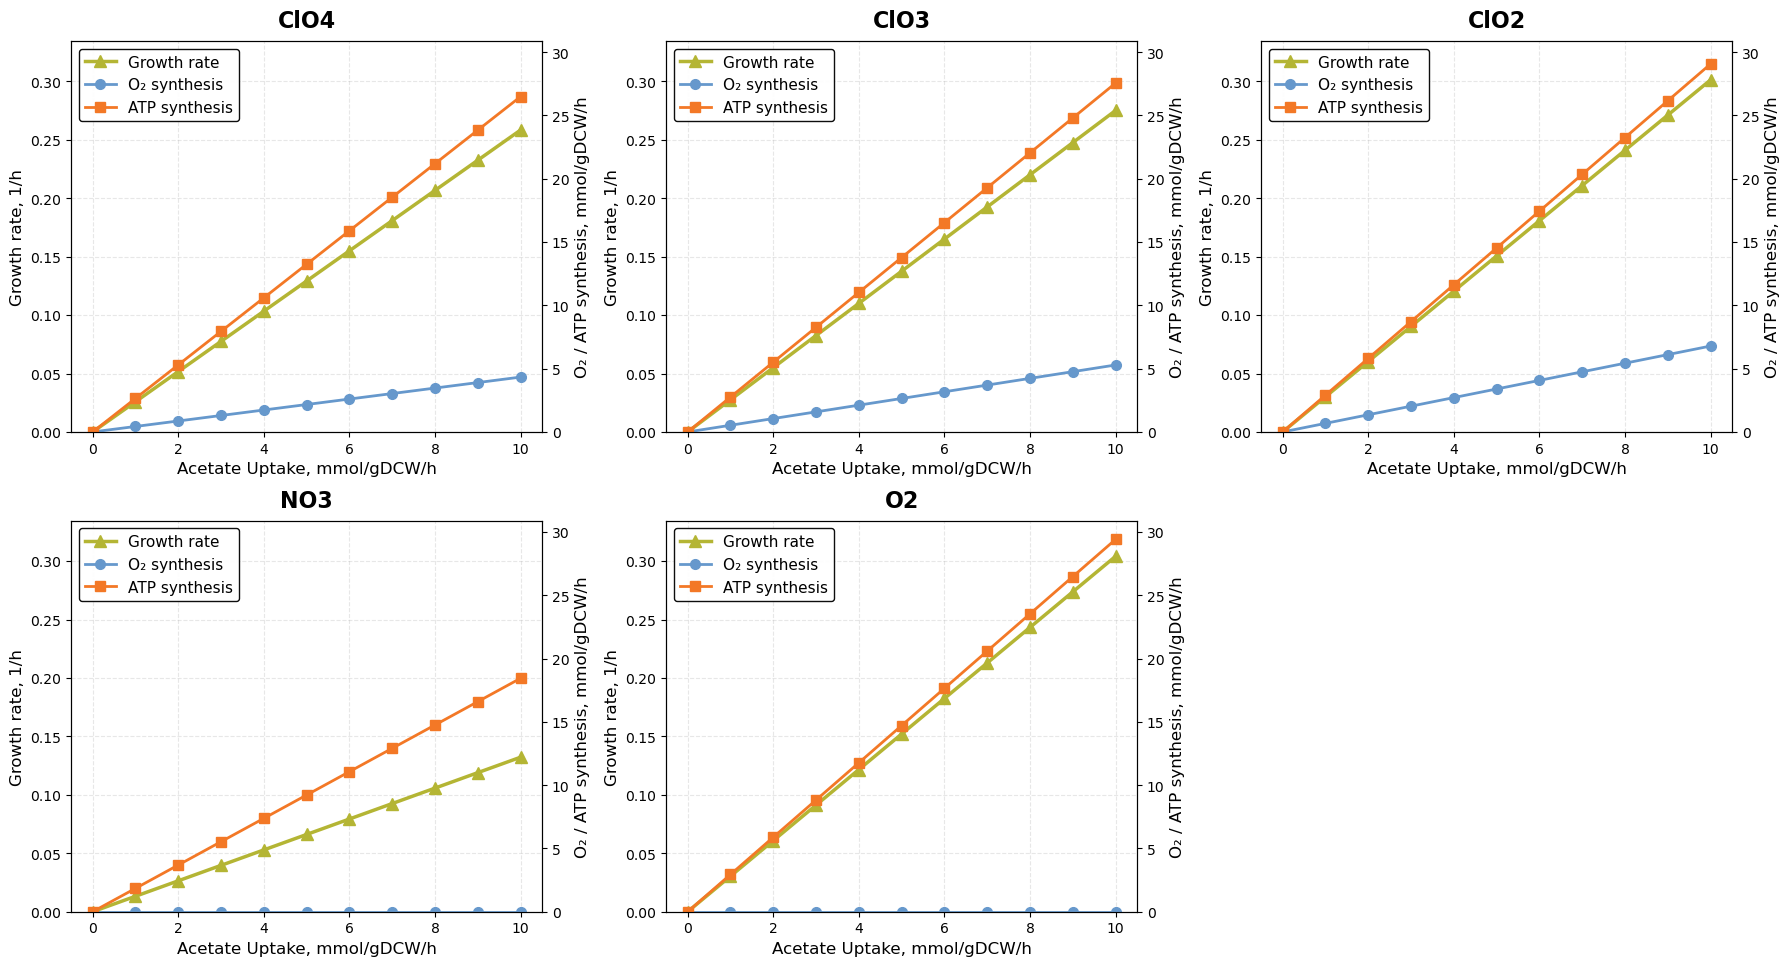

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

if 'df' not in locals():
    print("Error: DataFrame 'df' not found. Please run simulation first.")
    exit()

y_biomass_max = df['biomass'].max()
y_right_max = max(df['o2'].max(), df['atp'].max())

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten() 

conditions = ['ClO4', 'ClO3', 'ClO2', 'NO3', 'O2']

colors = {
    'biomass': '#B4B534',
    'o2': '#6698CC',
    'atp': '#F37826'
}

for idx, cond in enumerate(conditions):
    ax = axes[idx]
    df_cond = df[df['condition'] == cond]

    if df_cond.empty:
        ax.text(0.5, 0.5, f'No data for {cond}', 
                horizontalalignment='center',
                verticalalignment='center',
                transform=ax.transAxes, fontsize=14)
        ax.set_title(cond, fontsize=16, pad=10)
        continue
    
    line1 = ax.plot(df_cond['acetate_uptake'], df_cond['biomass'],
                    color=colors['biomass'], marker='^',
                    linewidth=2.5, markersize=8,
                    label='Growth rate', zorder=3)
    
    ax.set_xlabel('Acetate Uptake, mmol/gDCW/h', fontsize=12)
    ax.set_ylabel('Growth rate, 1/h', fontsize=12)
    ax.tick_params(axis='x', labelsize=10)
    ax.tick_params(axis='y', labelsize=10)
    ax.set_ylim(0, y_biomass_max * 1.1 if y_biomass_max > 0 else 1)
    ax.grid(True, alpha=0.3, linestyle='--', zorder=1)
    
    ax2 = ax.twinx()
    
    line2 = ax2.plot(df_cond['acetate_uptake'], df_cond['o2'],
                     color=colors['o2'], marker='o', 
                     linewidth=2, markersize=7,
                     label='O₂ synthesis')
    
    line3 = ax2.plot(df_cond['acetate_uptake'], df_cond['atp'],
                     color=colors['atp'], marker='s', 
                     linewidth=2, markersize=7,
                     label='ATP synthesis')
    
    ax2.set_ylabel('O₂ / ATP synthesis, mmol/gDCW/h', fontsize=12)
    ax2.tick_params(axis='y', labelsize=10)
    ax2.set_ylim(0, y_right_max * 1.05 if y_right_max > 0 else 1)
    
    ax.set_title(cond, fontsize=16, pad=10, fontweight='bold')
    
    lines = line1 + line2 + line3
    labels = [l.get_label() for l in lines]
    ax.legend(lines, labels, loc='upper left', fontsize=11, 
              framealpha=0.95, edgecolor='black')

if len(conditions) < 6:
    axes[-1].set_visible(False)

plt.tight_layout()
plt.subplots_adjust(top=0.93)
plt.show()

fig.savefig('acetate_response_lines_CYOO3_blocked_2.png', dpi=1200, bbox_inches='tight')

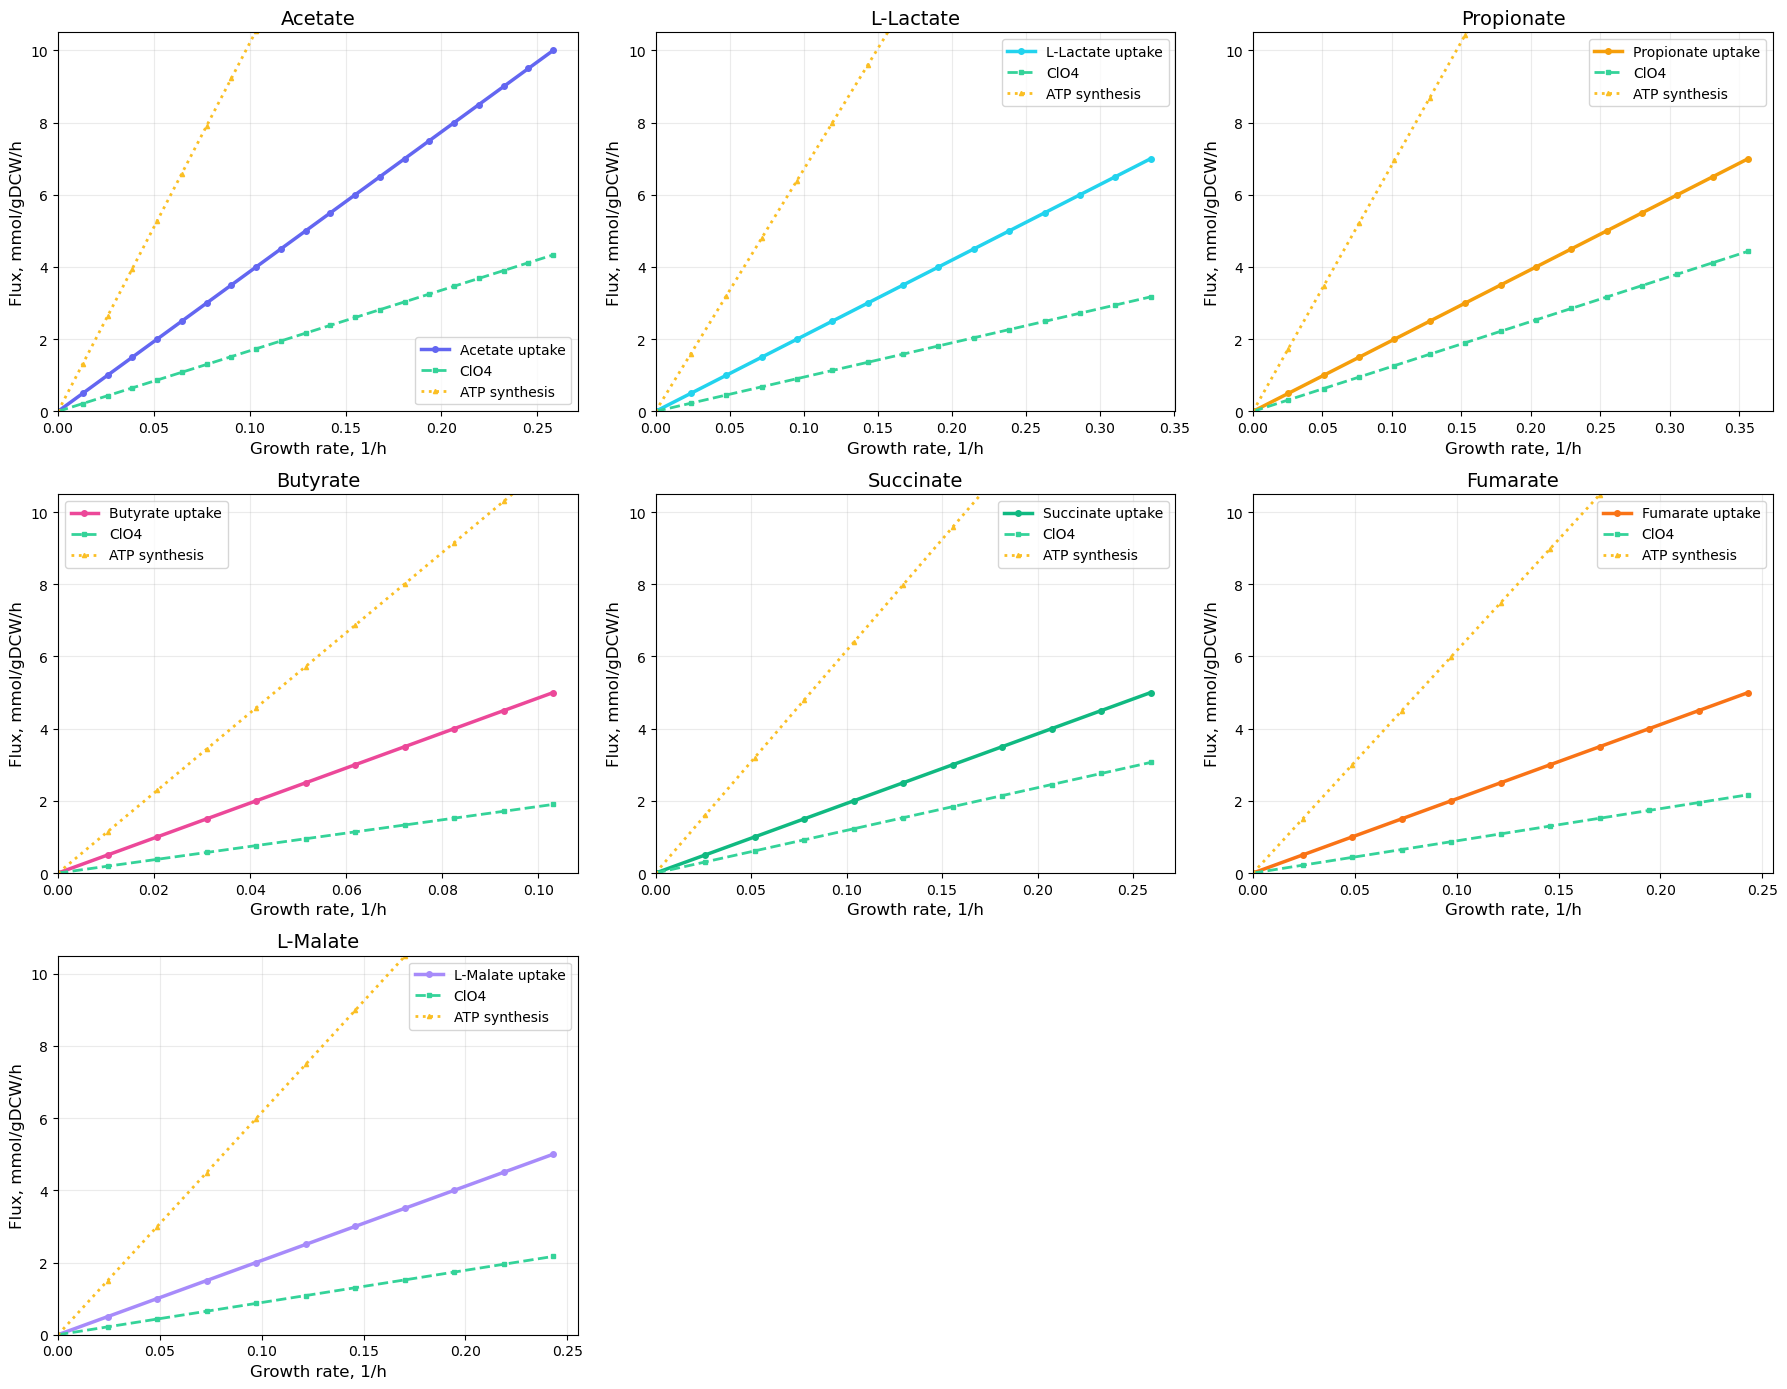

In [27]:
import matplotlib.pyplot as plt
import numpy as np

substrates = [
    ("EX_ac_e",     "Acetate",     "#6366f1", (-10, 0, 0.5)),    
    ("EX_lac__L_e", "L-Lactate",   "#22d3ee", (-7, 0, 0.5)),  
    ("EX_ppa_e",    "Propionate",  "#f59e0b", (-7, 0, 0.5)),  
    ("EX_but_e",    "Butyrate",    "#ec4899", (-5, 0, 0.5)),     
    ("EX_succ_e",   "Succinate",   "#10b981", (-5, 0, 0.5)),     
    ("EX_fum_e",    "Fumarate",    "#f97316", (-5, 0, 0.5)),     
    ("EX_mal__L_e", "L-Malate",    "#a78bfa", (-5, 0, 0.5)),     
]

agitata.reactions.EX_clo4_e.bounds = (-1000, 1000)
agitata.reactions.EX_o2_e.bounds  = (0, 1000)

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for idx, (rxn_id, label, color, (lb_min, lb_max, step)) in enumerate(substrates):
    ax = axes[idx]
    
    lb_range = np.arange(lb_min, lb_max + step/2, step)
    
    mu_vals, sub_vals, clo4_vals, atp_vals = [], [], [], []

    for lb in lb_range:

        for s_id, _, _, _ in substrates:
            agitata.reactions.get_by_id(s_id).bounds = (0, 1000)
        
        agitata.reactions.get_by_id(rxn_id).bounds = (lb, 1000)

        sol = agitata.optimize()

        if sol.status == "optimal":

            # Growth rate
            mu = sol.objective_value

            # Uptake 
            s_fl = abs(sol.fluxes.get(rxn_id, 0))

            # ClO4 uptake
            c_fl = abs(sol.fluxes.get("EX_clo4_e", 0))

            # ATP production
            atp = (
                agitata.metabolites.atp_c.summary()
                .producing_flux["flux"]
                .sum()
                .round(5)
            )

        else:
            mu = s_fl = c_fl = atp = 0.0

        mu_vals.append(mu)
        sub_vals.append(s_fl)
        clo4_vals.append(c_fl)
        atp_vals.append(atp)

    order = np.argsort(mu_vals)

    mu_s   = np.array(mu_vals)[order]
    sub_s  = np.array(sub_vals)[order]
    clo4_s = np.array(clo4_vals)[order]
    atp_s  = np.array(atp_vals)[order]

    ax.plot(
        mu_s,
        sub_s,
        color=color,
        lw=2.5,
        marker="o",
        ms=4,
        label=f"{label} uptake"
    )

    ax.plot(
        mu_s,
        clo4_s,
        color="#34d399",
        lw=2,
        marker="s",
        ms=3,
        ls="--",
        label="ClO4"
    )

    ax.plot(
        mu_s,
        atp_s,
        color="#fbbf24",
        lw=2,
        marker="^",
        ms=3,
        ls=":",
        label="ATP synthesis"
    )

    if len(mu_s) > 0 and mu_s[-1] > 0:
        ax.set_xlim(0, mu_s[-1] * 1.05)
    else:
        ax.set_xlim(0, 0.5)

    ax.set_ylim(0, 10.5)

    ax.set_xlabel("Growth rate, 1/h", fontsize=12)
    ax.set_ylabel("Flux, mmol/gDCW/h", fontsize=12)

    ax.set_title(f"{label}", fontsize=14)

    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.25)

for i in range(len(substrates), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.savefig("dif_substrates.png", dpi=1200, bbox_inches="tight")
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

data = [
    ("sample_1_8", 0.007, 0.034, 0.0),
    ("sample_1_9", 0.001, 0.009, 0.0),
    ("sample_2_2", 0.002, 0.000, 0.0),
    ("sample_2_3", 0.001, 0.000, 0.0),
    ("sample_3_2", 0.002, 0.005, 0.0),
    ("sample_3_3", 0.001, 0.006, 0.0),

    ("sample_1_8", 0.0515234122, 0.0726650277, 0.1),
    ("sample_1_9", 0.0773279280, 0.0275765656, 0.1),
    ("sample_2_2", 0.0048474423, 0.0302562366, 0.1),
    ("sample_2_3", 0.0102161078, 0.0398933077, 0.1),
    ("sample_3_2", 0.0123628784, 0.1024542383, 0.1),
    ("sample_3_3", 0.0265616438, 0.1062479556, 0.1),

    ("sample_1_8", 0.1917281588, 0.0951614462, 0.2),
    ("sample_1_9", 0.1570542600, 0.0455680702, 0.2),
    ("sample_2_2", 0.0069241461, 0.0615494397, 0.2),
    ("sample_2_3", 0.0200979274, 0.0801017293, 0.2),
    ("sample_3_2", 0.0236838293, 0.2052386209, 0.2),
    ("sample_3_3", 0.0531269312, 0.2125077106, 0.2),

    ("sample_1_8", 0.2914731560, 0.1337178086, 0.3),
    ("sample_1_9", 0.2367116035, 0.0638428473, 0.3),
    ("sample_2_2", 0.0103654130, 0.0923263269, 0.3),
    ("sample_2_3", 0.0300523561, 0.1202140292, 0.3),
    ("sample_3_2", 0.0342535908, 0.3082139781, 0.3),
    ("sample_3_3", 0.0796909736, 0.3187638235, 0.3),

    ("sample_1_8", 0.3897452995, 0.1756904173, 0.4),
    ("sample_1_9", 0.3160092224, 0.0835488536, 0.4),
    ("sample_2_2", 0.0136795896, 0.1231202322, 0.4),
    ("sample_2_3", 0.0400711113, 0.1602837310, 0.4),
    ("sample_3_2", 0.0456652789, 0.4109500114, 0.4),
    ("sample_3_3", 0.1062553810, 0.4250215995, 0.4),

    ("sample_1_8", 0.4884273024, 0.2167066618, 0.5),
    ("sample_1_9", 0.3953736785, 0.1029889553, 0.5),
    ("sample_2_2", 0.0171004533, 0.1539041673, 0.5),
    ("sample_2_3", 0.0500886662, 0.2003546008, 0.5),
    ("sample_3_2", 0.0574449132, 0.5136062608, 0.5),
    ("sample_3_3", 0.1328192838, 0.5312771403, 0.5),

    ("sample_1_8", 0.5866020212, 0.2589089972, 0.6),
    ("sample_1_9", 0.4746653072, 0.1227182802, 0.6),
    ("sample_2_2", 0.0326708164, 0.1944790991, 0.6),
    ("sample_2_3", 0.2252310731, 0.1983135559, 0.6),
    ("sample_3_2", 0.0684945955, 0.6164296075, 0.6),
    ("sample_3_3", 0.1594042477, 0.6375242258, 0.6),

    ("sample_1_8", 0.6848679621, 0.3008963624, 0.7),
    ("sample_1_9", 0.5539479398, 0.1424869886, 0.7),
    ("sample_2_2", 0.2402553949, 0.1862974248, 0.7),
    ("sample_2_3", 0.5015919038, 0.1686772489, 0.7),
    ("sample_3_2", 0.0799075812, 0.7191682382, 0.7),
    ("sample_3_3", 0.1859814144, 0.7437754863, 0.7),

    ("sample_1_8", 0.7829138923, 0.3433992478, 0.8),
    ("sample_1_9", 0.6332032221, 0.1623598715, 0.8),
    ("sample_2_2", 0.4296445677, 0.1772709074, 0.8),
    ("sample_2_3", 0.7853802435, 0.1382444328, 0.8),
    ("sample_3_2", 0.0913229260, 0.8219063428, 0.8),
    ("sample_3_3", 0.2125099968, 0.8500400106, 0.8),

    ("sample_1_8", 0.7604004377, 0.5785702727, 0.9),
    ("sample_1_9", 0.7123790089, 0.1825536981, 0.9),
    ("sample_2_2", 1.0705449190, 0.1467248202, 0.9),
    ("sample_2_3", 1.0691099622, 0.1078179020, 0.9),
    ("sample_3_2", 0.1027381783, 0.9246436600, 0.9),
    ("sample_3_3", 0.2390735791, 0.9562949067, 0.9),

    ("sample_1_8", 0.6858004377, 0.7931126527, 1.0),
    ("sample_1_9", 0.7744065510, 0.2275605332, 1.0),
    ("sample_2_2", 1.5774068198, 0.1150114683, 1.0),
    ("sample_2_3", 1.4007758993, 0.0703693944, 1.0),
    ("sample_3_2", 0.5404585099, 0.9669299686, 1.0),
    ("sample_3_3", 1.0325182113, 0.8571667729, 1.0),
]

df1 = pd.DataFrame(data, columns=["sample", "agitata_growth", "methanotroph_growth", "tradeoff"])

data = [
    ("sample_1_8", 1.0327894576184335, 2.7138945984622063, 0.0),
    ("sample_1_9", 0.6011817286236716, 1.802448551688071, 0.0),
    ("sample_2_2", 4.767917275621997, 10.53, 0.0),
    ("sample_2_3", 9.345267698486303, 9.36, 0.0),
    ("sample_3_2", np.nan, 0.2349797374277946, 0.0),
    ("sample_3_3", np.nan, 0.2846387269628438, 0.0),

    ("sample_1_8", 0.0049367564501087, 4.055843800782048, 0.1),
    ("sample_1_9", 0.0016338389278742, 4.470027136878753, 0.1),
    ("sample_2_2", 1.7066001141706666, 10.53, 0.1),
    ("sample_2_3", 2.1022850717930504, 9.36, 0.1),
    ("sample_3_2", np.nan, 5.0180323193977925, 0.1),
    ("sample_3_3", np.nan, 4.86478717101113, 0.1),

    ("sample_1_8", 0.0070995569457244, 10.074488691190272, 0.2),
    ("sample_1_9", 0.0028705271587421, 8.41958363366458, 0.2),
    ("sample_2_2", 7.368146330235499, 10.53, 0.2),
    ("sample_2_3", 5.35200117217882, 9.36, 0.2),
    ("sample_3_2", np.nan, 8.0, 0.2),
    ("sample_3_3", np.nan, 8.0, 0.2),

    ("sample_1_8", 0.0100886696959714, 14.746512189824678, 0.3),
    ("sample_1_9", 0.0041189587472402, 12.387974956733649, 0.3),
    ("sample_2_2", 5.397063940082685, 10.53, 0.3),
    ("sample_2_3", 1.527395748016805, 9.36, 0.3),
    ("sample_3_2", np.nan, 8.0, 0.3),
    ("sample_3_3", np.nan, 8.0, 0.3),

    ("sample_1_8", np.nan, 18.46, 0.4),
    ("sample_1_9", 0.0054266583095466, 16.402731161015602, 0.4),
    ("sample_2_2", 3.4256523551838605, 10.53, 0.4),
    ("sample_2_3", 0.6518000080521862, 9.36, 0.4),
    ("sample_3_2", np.nan, 8.0, 0.4),
    ("sample_3_3", np.nan, 8.0, 0.4),

    ("sample_1_8", np.nan, 18.46, 0.5),
    ("sample_1_9", np.nan, 18.140831872504883, 0.5),
    ("sample_2_2", 1.4541485797525535, 10.53, 0.5),
    ("sample_2_3", 7.308089517342696e-05, 11.078374496380562, 0.5),
    ("sample_3_2", np.nan, 8.0, 0.5),
    ("sample_3_3", np.nan, 8.0, 0.5),

    ("sample_1_8", np.nan, 18.46, 0.6),
    ("sample_1_9", np.nan, 18.10133802836363, 0.6),
    ("sample_2_2", 2.383941726349248e-05, 11.683197338485332, 0.6),
    ("sample_2_3", np.nan, 11.7, 0.6),
    ("sample_3_2", np.nan, 8.0, 0.6),
    ("sample_3_3", np.nan, 8.0, 0.6),

    ("sample_1_8", np.nan, 18.46, 0.7),
    ("sample_1_9", np.nan, 17.620534224378666, 0.7),
    ("sample_2_2", np.nan, 11.7, 0.7),
    ("sample_2_3", np.nan, 11.7, 0.7),
    ("sample_3_2", np.nan, 8.0, 0.7),
    ("sample_3_3", np.nan, 8.0, 0.7),

    ("sample_1_8", np.nan, 18.46, 0.8),
    ("sample_1_9", np.nan, 16.911479880154157, 0.8),
    ("sample_2_2", np.nan, 11.7, 0.8),
    ("sample_2_3", np.nan, 11.7, 0.8),
    ("sample_3_2", np.nan, 8.0, 0.8),
    ("sample_3_3", np.nan, 8.0, 0.8),

    ("sample_1_8", np.nan, 18.46, 0.9),
    ("sample_1_9", np.nan, 15.86242292607946, 0.9),
    ("sample_2_2", np.nan, 11.7, 0.9),
    ("sample_2_3", np.nan, 11.7, 0.9),
    ("sample_3_2", np.nan, 8.0, 0.9),
    ("sample_3_3", np.nan, 8.0, 0.9),

    ("sample_1_8", np.nan, 18.46, 1.0),
    ("sample_1_9", np.nan, 14.910873784546936, 1.0),
    ("sample_2_2", np.nan, 11.7, 1.0),
    ("sample_2_3", np.nan, 11.7, 1.0),
    ("sample_3_2", np.nan, 8.0, 1.0),
    ("sample_3_3", np.nan, 8.0, 1.0),
]

df2 = pd.DataFrame(data, columns=["sample", "ClO4", "CH4", "tradeoff"])

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax = axes[0]

x_agitata = df1["tradeoff"] - 0.012
x_methanotroph = df1["tradeoff"] + 0.012

ax.scatter(
    x_agitata,
    df1["agitata_growth"],
    color="crimson",
    s=45,
    alpha=0.8,
    label="D. agitata"
)

ax.scatter(
    x_methanotroph,
    df1["methanotroph_growth"],
    color="royalblue",
    s=45,
    alpha=0.8,
    label="Methanotroph"
)

def add_trend(ax, x, y, color):
    mask = np.isfinite(x) & np.isfinite(y)

    x = np.asarray(x)[mask]
    y = np.asarray(y)[mask]

    if len(x) > 1:
        coef = np.polyfit(x, y, 1)
        x_trend = np.linspace(x.min(), x.max(), 100)
        y_trend = np.polyval(coef, x_trend)

        ax.plot(
            x_trend,
            y_trend,
            color=color,
            linewidth=2,
            alpha=0.8
        )

add_trend(
    ax,
    df1["tradeoff"],
    df1["agitata_growth"],
    "crimson"
)

add_trend(
    ax,
    df1["tradeoff"],
    df1["methanotroph_growth"],
    "royalblue"
)

ax.set_xlabel("Tradeoff")
ax.set_ylabel("Growth rate")
ax.set_title("Growth rate")
ax.set_xlim(-0.05, 1.05)
ax.grid(alpha=0.25)
ax.legend()

ax = axes[1]

mask_clo4 = df2["ClO4"].notna()

x_clo4 = df2.loc[mask_clo4, "tradeoff"] - 0.012
y_clo4 = df2.loc[mask_clo4, "ClO4"]

ax.scatter(
    x_clo4,
    y_clo4,
    color="purple",
    s=45,
    alpha=0.8,
    label="ClO4"
)

mask_ch4 = df2["CH4"].notna()

x_ch4 = df2.loc[mask_ch4, "tradeoff"] + 0.012
y_ch4 = df2.loc[mask_ch4, "CH4"]

ax.scatter(
    x_ch4,
    y_ch4,
    color="darkorange",
    s=45,
    alpha=0.8,
    label="CH4"
)

add_trend(
    ax,
    df2.loc[mask_clo4, "tradeoff"],
    df2.loc[mask_clo4, "ClO4"],
    "purple"
)

add_trend(
    ax,
    df2.loc[mask_ch4, "tradeoff"],
    df2.loc[mask_ch4, "CH4"],
    "darkorange"
)

ax.set_xlabel("Tradeoff")
ax.set_ylabel("Flux")
ax.set_title("Substrate uptake")
ax.set_xlim(-0.05, 1.05)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.savefig("tradeoff.png", dpi=1200, bbox_inches="tight")
plt.show()